# 23CSE301 Machine Learning Capstone — Classification Track
## Edible or poisonous? Classifying mushrooms from 21 morphological attributes

**Dataset:** `data/raw/mushrooms.csv` (8,124 rows × 23 columns, all categorical) · **Target:** `class` (`e` = edible, `p` = poisonous)

| § | Content | Rubric |
|---|---|---|
| 1–5 | Problem, dataset, setup, loading, audit | R1-A1 |
| 6 | EDA for a fully categorical dataset | R1-A2, A3 |
| 7–10 | Cleaning, stratified split, feature engineering, leakage-safe pipeline | R1-B1–B3 |
| 11 | **Part A**: Logistic Regression, KNN, Gaussian NB, Decision Tree, SVC | R1-D1, D2 |
| 12 | **Part B**: Random Forest, AdaBoost, Gradient Boosting, Bagging, MLP | R2-A1 |
| 13 | Consolidated 10-algorithm comparison, confusion matrices, ROC curves | R2-A2 |
| 14–16 | Tuning summary, stratified CV, final model selection | R2-A3 |
| 17–19 | Saved pipelines, limitations, conclusion | Bonus |

**Reproducibility:** `random_state = 42`; one stratified 80:20 split shared by all ten classifiers.

> **AI-assistance notice.** The code scaffolding in this notebook was produced with an AI assistant (Claude). Under guideline 7.5, analysis and interpretation must be the team's own: every cell marked ✍️ **DRAFT** contains observations read off the computed outputs and **must be verified and rewritten by the team before submission**.

> ⚠️ **Safety.** This is a historical teaching dataset. No model here should ever be used to decide whether a real mushroom is safe to eat.

## 1. Problem statement

Given a mushroom's visible and olfactory characteristics (cap, gills, stalk, veil, ring, spores, odour, population and habitat), predict whether it is **edible (`e`)** or **poisonous (`p`)**.

The two kinds of error do not cost the same. Calling a poisonous mushroom edible can be fatal, while calling an edible one poisonous only wastes food. So besides the required weighted metrics, we track **recall on the poisonous class** and the **number of poisonous mushrooms predicted as edible** (false negatives with `p` as the positive class).

## 2. Dataset description

The UCI Machine Learning Repository *Mushroom* dataset (1987) describes hypothetical samples of 23 gilled mushroom species in the *Agaricus* and *Lepiota* families, drawn from *The Audubon Society Field Guide to North American Mushrooms* (1981). Every attribute is a one-letter code; for example, in `odor`: a = almond, l = anise, n = none, f = foul. The full code dictionary is in `src/config.py` (`MUSHROOM_CODE_LABELS`).

## 3. Imports and configuration

In [1]:
import sys
import warnings
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
from IPython.display import display
from scipy.stats import chi2_contingency
from sklearn.compose import ColumnTransformer
from sklearn.exceptions import ConvergenceWarning
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, log_loss, mutual_info_score, roc_curve
from sklearn.model_selection import cross_val_score, cross_validate as sk_cross_validate
from sklearn.naive_bayes import GaussianNB
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.tree import DecisionTreeClassifier, export_text, plot_tree

from src import config
from src.data_loader import column_audit, load_mushrooms
from src.evaluation import classification_metrics, score_for_roc
from src.feature_engineering import add_mushroom_features
from src.model_training import classification_specs, cross_validate, load_pipeline, run_model, save_pipeline, stratified_kfold
from src.preprocessing import classification_xy, make_classification_pipeline, train_test
from src.utils import load_json, save_json, slugify
from src.visualization import plot_confusion_grid, plot_feature_importance, plot_metric_bars, save_fig, set_plot_style

set_plot_style()
pd.set_option("display.width", 170)
pd.set_option("display.max_columns", 30)
pd.set_option("display.max_colwidth", 70)
RANDOM_STATE = config.RANDOM_STATE
np.random.seed(RANDOM_STATE)
TRACK = "classification"
POS = config.CLF_POSITIVE

print("Python      :", sys.version.split()[0], "|", sys.executable)
print("scikit-learn:", sklearn.__version__, "| pandas:", pd.__version__, "| numpy:", np.__version__)

Python      : 3.13.9 | C:\Users\HP\anaconda3\python.exe
scikit-learn: 1.7.2 | pandas: 2.3.3 | numpy: 2.3.5


## 4. Loading the data

In [2]:
df = load_mushrooms()
print(f"Loaded {config.DATASET_FILES['mushrooms'].name}: {df.shape[0]} rows x {df.shape[1]} columns")
df.head()

Loaded mushrooms.csv: 8124 rows x 23 columns


,class,cap-shape,cap-surface,cap-color,bruises,odor,gill-attachment,gill-spacing,gill-size,gill-color,stalk-shape,stalk-root,stalk-surface-above-ring,stalk-surface-below-ring,stalk-color-above-ring,stalk-color-below-ring,veil-type,veil-color,ring-number,ring-type,spore-print-color,population,habitat
0,p,x,s,n,t,p,f,c,n,k,e,e,s,s,w,w,p,w,o,p,k,s,u
1,e,x,s,y,t,a,f,c,b,k,e,c,s,s,w,w,p,w,o,p,n,n,g
2,e,b,s,w,t,l,f,c,b,n,e,c,s,s,w,w,p,w,o,p,n,n,m
3,p,x,y,w,t,p,f,c,n,n,e,e,s,s,w,w,p,w,o,p,k,s,u
4,e,x,s,g,f,n,f,w,b,k,t,e,s,s,w,w,p,w,o,e,n,a,g


## 5. Dataset audit (A1)

In [3]:
audit = column_audit(df)
audit["levels"] = [", ".join(sorted(df[c].unique())) for c in df.columns]
display(audit[["column", "dtype", "missing", "sentinel_coded", "n_unique", "constant", "levels"]])
print("NaN cells                         :", int(df.isna().sum().sum()))
print("Cells coded '?'                   :", int((df == "?").sum().sum()), "-> all in", list(df.columns[(df == "?").any()]))
print("Duplicate rows                    :", int(df.duplicated().sum()))
conflicts = df.groupby([c for c in df.columns if c != config.CLF_TARGET])[config.CLF_TARGET].nunique().gt(1).sum()
print("Identical features, different class:", int(conflicts))
print("Constant columns                  :", audit.loc[audit["constant"], "column"].tolist())

,column,dtype,missing,sentinel_coded,n_unique,constant,levels
0,class,object,0,0,2,False,"e, p"
1,cap-shape,object,0,0,6,False,"b, c, f, k, s, x"
2,cap-surface,object,0,0,4,False,"f, g, s, y"
3,cap-color,object,0,0,10,False,"b, c, e, g, n, p, r, u, w, y"
4,bruises,object,0,0,2,False,"f, t"
5,odor,object,0,0,9,False,"a, c, f, l, m, n, p, s, y"
6,gill-attachment,object,0,0,2,False,"a, f"
7,gill-spacing,object,0,0,2,False,"c, w"
8,gill-size,object,0,0,2,False,"b, n"
9,gill-color,object,0,0,12,False,"b, e, g, h, k, n, o, p, r, u, w, y"


NaN cells                         : 0
Cells coded '?'                   : 2480 -> all in ['stalk-root']
Duplicate rows                    : 0
Identical features, different class: 0
Constant columns                  : ['veil-type']


,count,percent,meaning
class,,,
e,4208,51.8,edible
p,3916,48.2,poisonous


Majority-class baseline accuracy: 0.5180


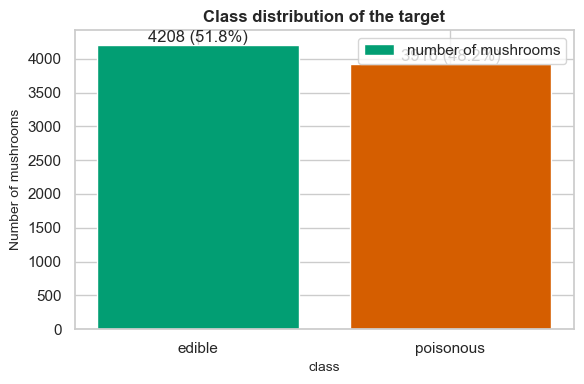

In [4]:
counts = df[config.CLF_TARGET].value_counts()
display(pd.DataFrame({"count": counts, "percent": (counts / len(df) * 100).round(2),
                      "meaning": counts.index.map(config.CLF_CLASS_LABELS)}))
print(f"Majority-class baseline accuracy: {counts.max() / len(df):.4f}")

fig, ax = plt.subplots(figsize=(6, 4))
bars = ax.bar([config.CLF_CLASS_LABELS[c] for c in counts.index], counts.values,
              color=[sns.color_palette()[2], sns.color_palette()[3]], label="number of mushrooms")
ax.bar_label(bars, labels=[f"{v} ({v / len(df):.1%})" for v in counts.values])
ax.set(title="Class distribution of the target", xlabel="class", ylabel="Number of mushrooms"); ax.legend()
fig.tight_layout(); save_fig(fig, TRACK, "eda_class_distribution"); plt.show()

### Observation — audit
- 8,124 rows, 22 features plus the target, every one a single-letter category. There are **no `NaN` cells**, but `stalk-root` uses **`?` for 2,480 rows (30.5%)**, a missing value that pandas cannot detect on its own.
- `veil-type` has a single level (`p`) in every row, so it carries no information.
- There are no duplicate rows and no pairs of identical feature vectors with different labels, so the data contains no label noise.
- Classes are nearly balanced (51.8% edible / 48.2% poisonous). Accuracy is therefore a meaningful metric, and the majority-class baseline is 0.518.

> ✍️ **DRAFT – rewrite in your own words.** The numbers come from the output above; the wording is AI-drafted and must be checked and rewritten by the team (guideline 7.5).

## 6. Exploratory data analysis (A2, A3)
### 6.1 Distribution of every feature, split by class

For categorical data, a count plot per feature is the equivalent of a histogram. Colouring each bar by class shows the feature–target relationship at the same time.

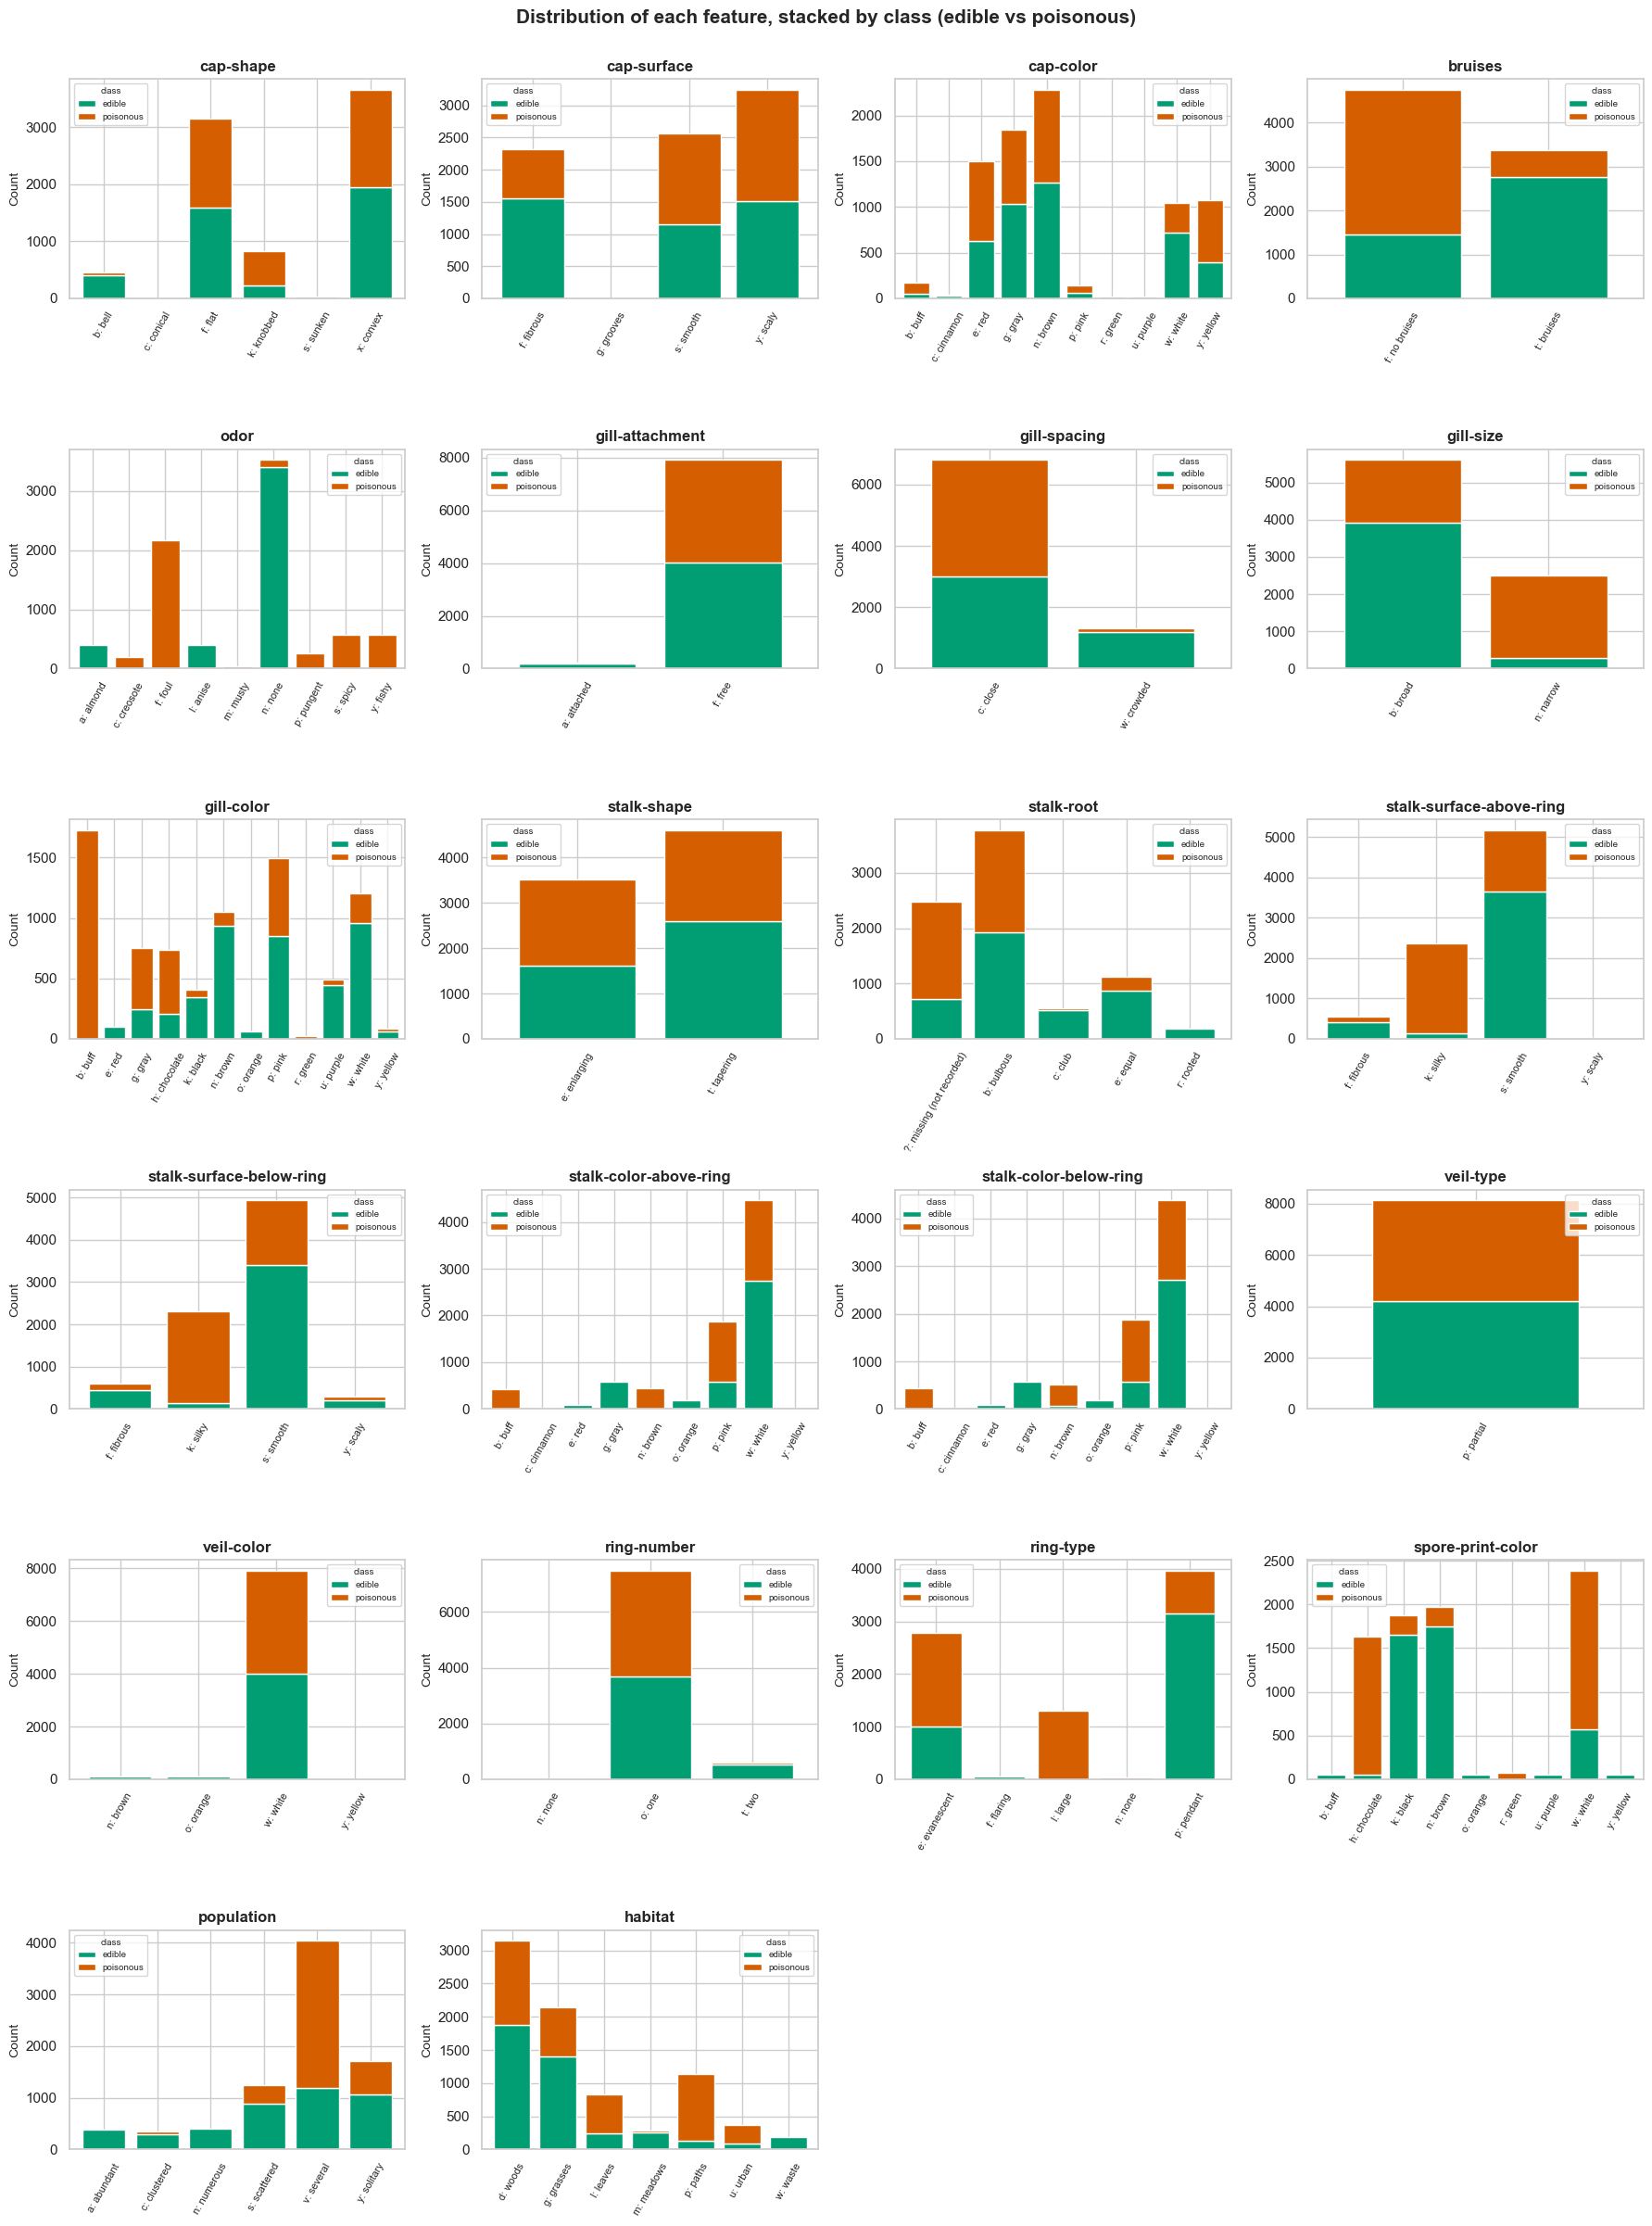

In [5]:
features_all = [c for c in df.columns if c != config.CLF_TARGET]
fig, axes = plt.subplots(6, 4, figsize=(18, 24))
for ax, col in zip(axes.ravel(), features_all):
    ct = pd.crosstab(df[col], df[config.CLF_TARGET])
    ct.index = [f"{i}: {config.MUSHROOM_CODE_LABELS[col].get(i, i)}" for i in ct.index]
    ct.rename(columns=config.CLF_CLASS_LABELS).plot.bar(stacked=True, ax=ax, color=[sns.color_palette()[2], sns.color_palette()[3]], width=0.8)
    ax.set(title=col, xlabel="", ylabel="Count")
    ax.tick_params(axis="x", rotation=60, labelsize=8)
    ax.legend(fontsize=7, title="class", title_fontsize=7)
for ax in axes.ravel()[len(features_all):]:
    ax.axis("off")
fig.suptitle("Distribution of each feature, stacked by class (edible vs poisonous)", fontsize=15, fontweight="bold", y=1.0)
fig.tight_layout(); save_fig(fig, TRACK, "eda_feature_distributions_by_class"); plt.show()

### Observation — feature distributions
- `veil-type` is a single bar (constant). `gill-attachment`, `veil-color` and `ring-number` are dominated by one level (each above 90%), so they carry little information.
- Several features split the classes almost perfectly. For `odor`, almond (`a`) and anise (`l`) bars are entirely edible, while foul (`f`), fishy (`y`), spicy (`s`), pungent (`p`), creosote (`c`) and musty (`m`) are entirely poisonous. `spore-print-color` and `gill-color` show similar but weaker separation.
- `stalk-root = ?` is visibly dominated by poisonous mushrooms, which is examined in §7.

> ✍️ **DRAFT – rewrite in your own words.** The numbers come from the output above; the wording is AI-drafted and must be checked and rewritten by the team (guideline 7.5).

### 6.2 Association heatmap (Cramér's V)

Pearson correlation is undefined for nominal codes. **Cramér's V** is the categorical analogue: $V = \sqrt{\chi^2 / (n \cdot (\min(r, c) - 1))}$, where $\chi^2$ comes from the contingency table of two variables. It ranges from 0 (independent) to 1 (perfectly associated).

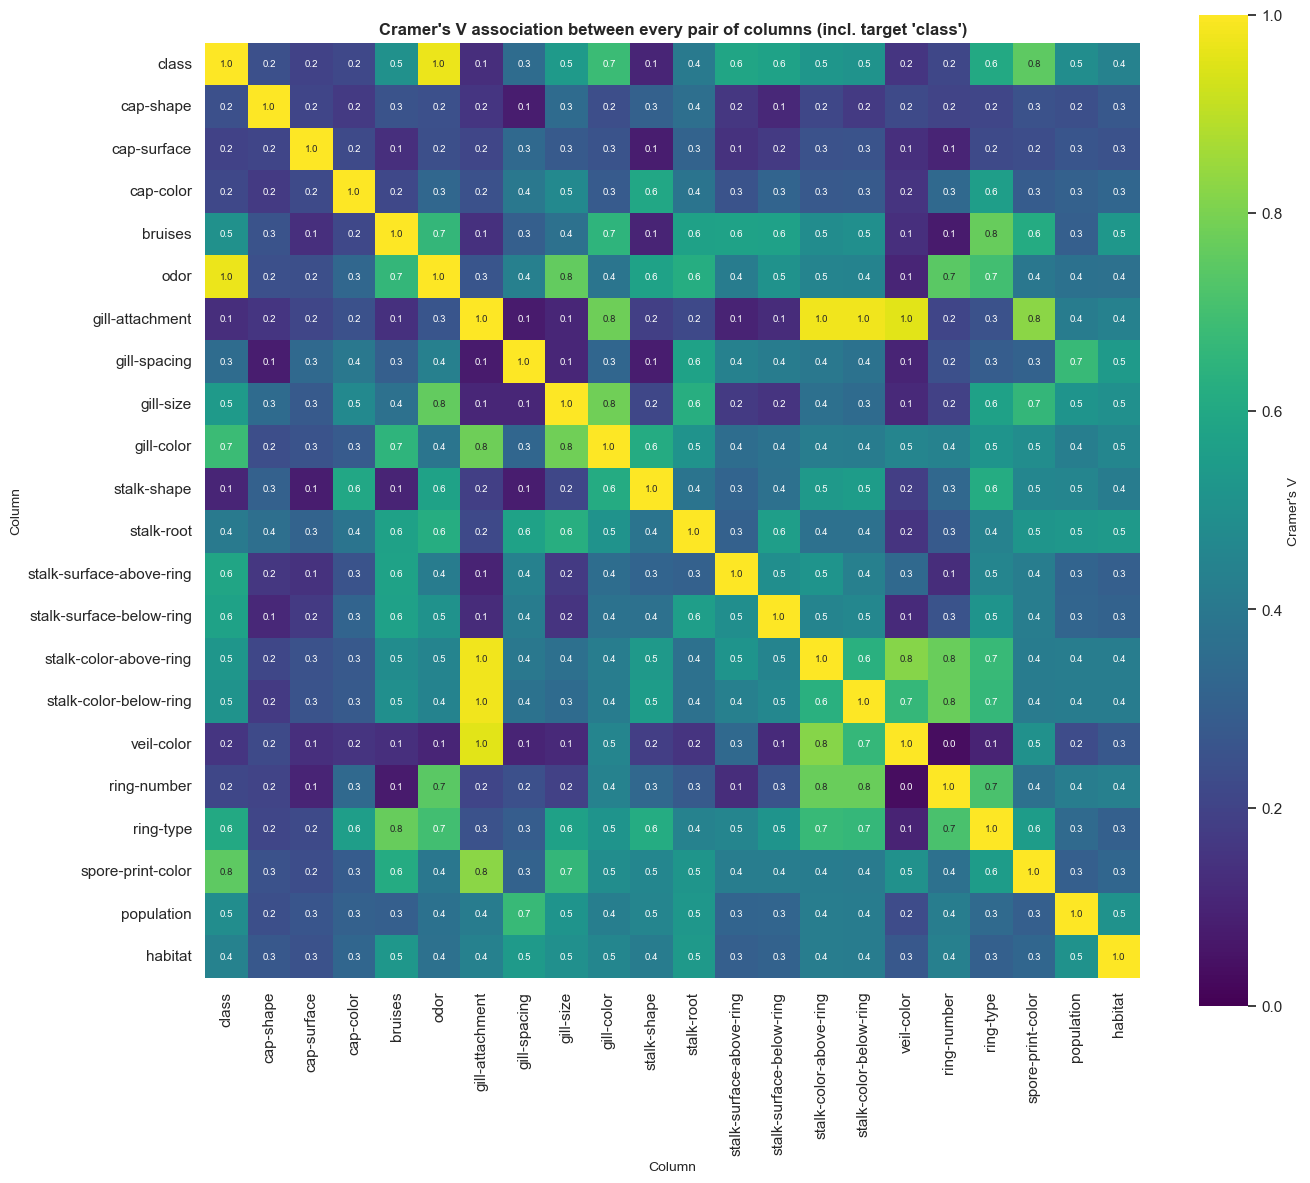

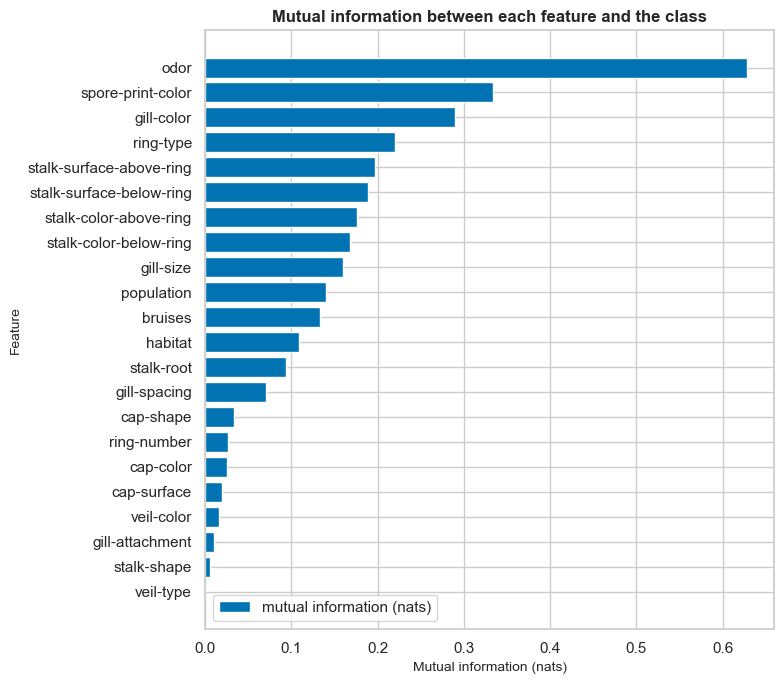

Strongest associations with the class (Cramer's V):
odor                        0.971
spore-print-color           0.753
gill-color                  0.681
ring-type                   0.603
stalk-surface-above-ring    0.588
stalk-surface-below-ring    0.575


In [6]:
def cramers_v(a, b):
    table = pd.crosstab(a, b)
    if min(table.shape) < 2:
        return 0.0
    chi2 = chi2_contingency(table, correction=False)[0]
    return float(np.sqrt(chi2 / (table.values.sum() * (min(table.shape) - 1))))

cols = [c for c in df.columns if c != "veil-type"]   # constant column: V is undefined
assoc = pd.DataFrame([[cramers_v(df[a], df[b]) for b in cols] for a in cols], index=cols, columns=cols)
fig, ax = plt.subplots(figsize=(14, 12))
sns.heatmap(assoc, cmap="viridis", vmin=0, vmax=1, square=True, annot=True, fmt=".1f", annot_kws={"size": 7},
            cbar_kws={"label": "Cramer's V"}, ax=ax)
ax.set(title="Cramer's V association between every pair of columns (incl. target 'class')", xlabel="Column", ylabel="Column")
fig.tight_layout(); save_fig(fig, TRACK, "eda_cramers_v_heatmap"); plt.show()

mi = pd.Series({c: mutual_info_score(df[c], df[config.CLF_TARGET]) for c in features_all}).sort_values()
fig, ax = plt.subplots(figsize=(8, 7))
ax.barh(mi.index, mi.values, color=sns.color_palette()[0], label="mutual information (nats)")
ax.set(title="Mutual information between each feature and the class", xlabel="Mutual information (nats)", ylabel="Feature"); ax.legend()
fig.tight_layout(); save_fig(fig, TRACK, "eda_mutual_information"); plt.show()
print("Strongest associations with the class (Cramer's V):")
print(assoc[config.CLF_TARGET].drop(config.CLF_TARGET).sort_values(ascending=False).head(6).round(3).to_string())

### Observation — associations
- `odor` has by far the strongest association with the class (Cramér's V ≈ 0.97, and the highest mutual information). `spore-print-color`, `gill-color` and `ring-type` follow.
- Several features are strongly associated **with each other**, notably the stalk-surface and stalk-colour pairs above and below the ring. This matters for Gaussian Naive Bayes, whose conditional-independence assumption these dependencies violate (§11.3). It also motivates the engineered feature in §9.

> ✍️ **DRAFT – rewrite in your own words.** The numbers come from the output above; the wording is AI-drafted and must be checked and rewritten by the team (guideline 7.5).

### 6.3 How far does a single feature go? The `odor` cross-tab

In [7]:
odor = pd.crosstab(df["odor"], df[config.CLF_TARGET], margins=True)
odor["% poisonous"] = (odor["p"] / odor["All"] * 100).round(1)
odor["meaning"] = [config.MUSHROOM_CODE_LABELS["odor"].get(i, "") for i in odor.index]
display(odor)
odor_only = cross_val_score(Pipeline([("oh", OneHotEncoder(handle_unknown="ignore")), ("tree", DecisionTreeClassifier(random_state=RANDOM_STATE))]),
                            df[["odor"]], df[config.CLF_TARGET], cv=stratified_kfold(), scoring="accuracy")
print(f"5-fold CV accuracy of a tree that sees ONLY odor: {odor_only.mean():.4f}")

class,e,p,All,% poisonous,meaning
odor,,,,,
a,400,0,400,0.0,almond
c,0,192,192,100.0,creosote
f,0,2160,2160,100.0,foul
l,400,0,400,0.0,anise
m,0,36,36,100.0,musty
n,3408,120,3528,3.4,none
p,0,256,256,100.0,pungent
s,0,576,576,100.0,spicy
y,0,576,576,100.0,fishy


5-fold CV accuracy of a tree that sees ONLY odor: 0.9852


### Observation — the dataset is almost separable
Eight of the nine odour levels are 100% one class. Only `n` (no odour) is mixed, at about 3.4% poisonous. A tree that sees **odour alone** already reaches about 98.5% CV accuracy. So we should expect near-perfect scores from most classifiers. That would show that the dataset is almost separable, not that the modelling is exceptional. The interesting differences will lie in how *reliably* each model reaches that ceiling and in its errors on the poisonous class.

> ✍️ **DRAFT – rewrite in your own words.** The numbers come from the output above; the wording is AI-drafted and must be checked and rewritten by the team (guideline 7.5).

## 7. Data cleaning (B1)
### 7.1 The `?` values in `stalk-root`

In [8]:
q = df["stalk-root"] == "?"
display(pd.crosstab(np.where(q, "stalk-root = ?", "stalk-root recorded"), df[config.CLF_TARGET], margins=True))
print(f"Poisonous rate when stalk-root is '?'      : {(df.loc[q, 'class'] == 'p').mean():.1%}")
print(f"Poisonous rate when stalk-root is recorded : {(df.loc[~q, 'class'] == 'p').mean():.1%}")

class,e,p,All
row_0,,,
stalk-root = ?,720,1760,2480
stalk-root recorded,3488,2156,5644
All,4208,3916,8124


Poisonous rate when stalk-root is '?'      : 71.0%
Poisonous rate when stalk-root is recorded : 38.2%


### Decision — keep `?` as its own category
The missingness is **not random**: 71.0% of mushrooms with `stalk-root = ?` are poisonous, against 38.2% of the rest. The options considered were:
- **Drop the 2,480 rows.** Rejected: that discards 30.5% of the data, and the discarded rows are disproportionately poisonous.
- **Impute the most frequent level (`b`).** Rejected: it would erase a signal that is itself predictive and invent root types that were never observed.
- **Keep `?` as a level.** ✔ One-hot encoding turns it into a `stalk-root_?` column meaning "root type not recorded". This keeps the information and needs no learned statistic, so it cannot leak.

A `SimpleImputer(most_frequent)` still sits inside the pipeline as a safeguard against genuine `NaN`s at prediction time. It is fitted on training data only and is a no-op on this data.

> ✍️ **DRAFT – rewrite in your own words.** The numbers come from the output above; the wording is AI-drafted and must be checked and rewritten by the team (guideline 7.5).

### 7.2 Duplicates, constant and near-constant columns, outliers
- **Duplicates:** 0 duplicate rows and 0 conflicting feature vectors (§5), so nothing is removed.
- **Constant column:** `veil-type` is dropped. It is simply not selected in `config.CLF_FEATURES`, so it never reaches a model.
- **Near-constant columns** (`gill-attachment`, `veil-color`, `ring-number`) are **kept**. Their rare levels are often informative, for example `veil-color = y` (8 rows).
- **Outliers:** there are no numeric features, so the categorical analogue is *rare levels*. Several levels have fewer than 10 rows (for example `cap-shape = c`, `cap-surface = g`). They are kept, and `OneHotEncoder(handle_unknown="ignore")` makes sure a level that is absent from the training split cannot crash prediction.

In [9]:
rare = [(c, lvl, n) for c in config.CLF_FEATURES for lvl, n in df[c].value_counts().items() if n < 20]
display(pd.DataFrame(rare, columns=["feature", "level", "rows"]).assign(
    meaning=lambda t: [config.MUSHROOM_CODE_LABELS[f].get(l, "") for f, l in zip(t["feature"], t["level"])]))

,feature,level,rows,meaning
0,cap-shape,c,4,conical
1,cap-surface,g,4,grooves
2,cap-color,u,16,purple
3,cap-color,r,16,green
4,stalk-color-above-ring,y,8,yellow
5,veil-color,y,8,yellow


## 8. Stratified train/test split (B2)

The split comes first; nothing is fitted before it. `stratify=y` preserves the 51.8 / 48.2 class ratio exactly in both parts, so the class balance does not vary between train and test because of random chance.

The target is encoded as an integer: **0 = edible, 1 = poisonous**, so poisonous is the positive class. Integer labels are conventional. They also avoid a scikit-learn 1.7.2 bug that we hit: `KNeighborsClassifier(metric="manhattan", weights="uniform")` crashes at prediction time when the labels are strings.

In [10]:
X, y = classification_xy(df)
X_train, X_test, y_train, y_test = train_test(X, y, stratify=True)
display(pd.DataFrame({"train": y_train.value_counts(normalize=True), "test": y_test.value_counts(normalize=True)}).round(4))
print(f"X_train {X_train.shape} | X_test {X_test.shape}")
only_in_test = [(c, l) for c in config.CLF_FEATURES for l in set(X_test[c]) - set(X_train[c])]
print("Category levels present in TEST but never seen in TRAIN:", only_in_test or "none")

,train,test
class,,
0,0.5179,0.5182
1,0.4821,0.4818


X_train (6499, 21) | X_test (1625, 21)
Category levels present in TEST but never seen in TRAIN: none


## 9. Feature engineering (B3)

§6.2 showed that the stalk looks the same above and below the ring for most mushrooms. A **mismatch** between the two sides is a *relationship* between columns, which no single one-hot column can express. We create

`stalk_ring_asymmetry` = (surface above ≠ surface below) + (colour above ≠ colour below), giving a value of 0, 1 or 2.

It is evaluated on the **training set only**.

In [11]:
train_fe = add_mushroom_features(X_train)
tab = pd.crosstab(train_fe["stalk_ring_asymmetry"], y_train)
tab["% poisonous"] = (tab[1] / tab.sum(axis=1) * 100).round(1)
display(tab)
print(f"Mutual information with class (train): {mutual_info_score(train_fe['stalk_ring_asymmetry'], y_train):.4f} nats")

def cv_with_and_without(model):
    base = Pipeline([("oh", ColumnTransformer([("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), config.CLF_FEATURES)])),
                     ("model", model)])
    with_fe = Pipeline([("fe", make_classification_pipeline(model).named_steps["features"]),
                        ("oh", ColumnTransformer([("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), config.CLF_FEATURES),
                                                  ("num", "passthrough", config.CLF_ENGINEERED)])),
                        ("model", model)])
    f1 = lambda p: cross_val_score(p, X_train, y_train, cv=stratified_kfold(), scoring="f1_weighted").mean()
    return f1(base), f1(with_fe)

rows = []
for label, model in [("Gaussian NB (default)", GaussianNB()), ("Logistic Regression, C=0.01 (strongly regularised)", LogisticRegression(C=0.01, max_iter=5000))]:
    without, with_ = cv_with_and_without(model)
    rows.append({"model": label, "CV F1 without feature": without, "CV F1 with feature": with_, "change": with_ - without})
display(pd.DataFrame(rows).round(5))

class,0,1,% poisonous
stalk_ring_asymmetry,,,
0,1712,1240,42.0
1,1636,1512,48.0
2,18,381,95.5


Mutual information with class (train): 0.0368 nats


,model,CV F1 without feature,CV F1 with feature,change
0,Gaussian NB (default),0.95397,0.95813,0.00417
1,"Logistic Regression, C=0.01 (strongly regularised)",0.98399,0.98415,0.00015


### Feature-engineering decision
- **Accepted: `stalk_ring_asymmetry`.** In the training set, mushrooms whose stalk differs on **both** attributes above vs below the ring (value 2) are **95.5% poisonous** (381 of 399), against 42.0% and 48.0% for values 0 and 1. That is a strong signal concentrated in a small group.
- **Measured effect (stratified 5-fold CV on the training set):** weighted F1 rises from 0.95397 to 0.95813 (+0.0042) for Gaussian NB, and from 0.98399 to 0.98415 (+0.0002) for a strongly regularised logistic regression. The gains are small because the one-hot features already separate the classes almost perfectly. The feature helps most for the weakest model, which cannot learn interactions between columns on its own.

The feature is row-wise comparison only: no target values and no cross-row statistics are involved, so it is **leakage-free by construction**. It runs inside every saved pipeline (`src/feature_engineering.add_mushroom_features`).

> ✍️ **DRAFT – rewrite in your own words.** The numbers come from the output above; the wording is AI-drafted and must be checked and rewritten by the team (guideline 7.5).

## 10. The leakage-safe preprocessing pipeline

`features` (adds `stalk_ring_asymmetry`) → `preprocess` = ColumnTransformer:
- **21 categorical features:** most-frequent imputer → `OneHotEncoder(handle_unknown="ignore")`. The codes are **nominal** (there is no order between "almond" and "foul"), so one-hot encoding is correct, and ordinal or label encoding would invent a false ordering.
- **Engineered numeric feature:** median imputer → `StandardScaler`. Distance- and gradient-based models (KNN, SVC, MLP, Logistic Regression) need comparable scales; one-hot columns are already 0/1.

→ `model`. Every learned step is fitted on the training rows only. The check below confirms it.

In [12]:
demo = make_classification_pipeline(LogisticRegression(max_iter=5000)).fit(X_train, y_train)
display(demo)
pre = demo.named_steps["preprocess"]
enc = pre.named_transformers_["cat"].named_steps["onehot"]
scaler = pre.named_transformers_["num"].named_steps["scale"]
print("Encoder levels == TRAIN levels:", all(set(cats) == set(X_train[c]) for c, cats in zip(config.CLF_FEATURES, enc.categories_)))
print("Scaler mean == TRAIN mean     :", np.isclose(scaler.mean_[0], add_mushroom_features(X_train)["stalk_ring_asymmetry"].mean()))
print("Scaler mean == FULL-data mean :", np.isclose(scaler.mean_[0], add_mushroom_features(X)["stalk_ring_asymmetry"].mean()))
feature_names = pre.get_feature_names_out()
print(f"Design matrix: {len(feature_names)} columns (one-hot levels + 1 engineered)")

,steps,"[('features', ...), ('preprocess', ...), ...]"
,transform_input,None
,memory,None
,verbose,False
,func,<function add...00280996E8FE0>
,inverse_func,None
,validate,False
,accept_sparse,False
,check_inverse,True
,feature_names_out,None
,kw_args,None


Encoder levels == TRAIN levels: True
Scaler mean == TRAIN mean     : True
Scaler mean == FULL-data mean : False
Design matrix: 117 columns (one-hot levels + 1 engineered)


## 11. Classification Part A (D1, D2)

**Protocol, identical for every model** (`src/model_training.run_model`):
1. Fit a **baseline** with library defaults and score it on the test set.
2. **Tune** with `GridSearchCV` using **stratified 5-fold CV on the training set**, scoring weighted F1.
3. Score the tuned best estimator on the same test set.

**Metrics** (`src/evaluation.classification_metrics`): Accuracy, weighted Precision, weighted Recall, weighted F1 and ROC-AUC. ROC-AUC is binary here, so no One-vs-Rest averaging is needed; it is computed from `predict_proba` for the poisonous class. For every model we also record the confusion matrix, recall on the poisonous class, and the **number of poisonous mushrooms predicted edible**.

In [13]:
specs = {s.name: s for s in classification_specs()}
display(pd.DataFrame([{"model": s.name, "part": "A" if i < 5 else "B", "baseline": s.baseline_note,
                       "grid": {k.split("__")[-1]: v for k, v in s.param_grid.items()}} for i, s in enumerate(specs.values())]))

runs = {}

def clf_metric(model, X_, y_):
    scores, _ = score_for_roc(model, X_)
    pred = model.predict(X_)
    m = classification_metrics(y_, pred, scores, model.classes_)
    m["Poisonous recall"] = float(((pred == POS) & (y_ == POS)).sum() / (y_ == POS).sum())
    m["Poisonous predicted edible"] = int(((pred != POS) & (y_ == POS)).sum())
    return m

def train(name):
    r = run_model(specs[name], X_train, y_train, X_test, y_test, clf_metric, stratified_kfold(), "f1_weighted")
    r["confusion"] = confusion_matrix(y_test, r["final_model"].predict(X_test), labels=[0, 1])
    runs[name] = r
    rows = {"baseline (test)": r["baseline_test"]}
    if r["search"] is not None:
        rows["tuned (test)"] = r["tuned_test"]
        print(f"Best parameters (stratified 5-fold CV on train): {r['best_params']} | best CV F1 = {r['best_cv_score']:.5f}")
    rows["final model (train)"] = r["final_train"]
    display(pd.DataFrame(rows).T.round(5))
    print("Confusion matrix on test (rows = actual edible/poisonous, columns = predicted edible/poisonous):")
    print(r["confusion"])
    return r

def cv_table(r, top=8):
    res = pd.DataFrame(r["search"].cv_results_)
    cols = [c for c in res.columns if c.startswith("param_")] + ["mean_test_score", "std_test_score"]
    out = res.sort_values("rank_test_score")[cols].head(top)
    out.columns = [c.replace("param_", "").split("__")[-1] for c in out.columns]
    return out

,model,part,baseline,grid
0,Logistic Regression,A,library defaults,"{'C': [0.001, 0.01, 0.1, 1, 10, 100]}"
1,K-Nearest Neighbors,A,library defaults,"{'n_neighbors': [1, 3, 5, 7, 9, 11, 15, 21], 'weights': ['uniform'..."
2,Gaussian Naive Bayes,A,library defaults,"{'var_smoothing': [1e-12, 1e-11, 1e-10, 1e-09, 1e-08, 1e-07, 1e-06..."
3,Decision Tree,A,library defaults,"{'max_depth': [2, 3, 4, 5, 6, 8, None], 'criterion': ['gini', 'ent..."
4,Support Vector Machine (SVC),A,library defaults,"{'C': [0.01, 0.1, 1, 10], 'kernel': ['linear', 'rbf']}"
5,Random Forest,B,library defaults,"{'n_estimators': [25, 50, 100, 200], 'max_depth': [None, 5, 10], '..."
6,AdaBoost,B,library defaults,"{'n_estimators': [25, 50, 100, 200], 'learning_rate': [0.1, 0.5, 1..."
7,Gradient Boosting,B,library defaults,"{'n_estimators': [50, 100, 200], 'learning_rate': [0.05, 0.1, 0.2]..."
8,Bagging (Decision Tree),B,library defaults with a DecisionTreeClassifier base estimator,"{'n_estimators': [10, 25, 50, 100], 'max_samples': [0.5, 1.0], 'ma..."
9,MLP Neural Network,B,"library defaults (100 hidden units, relu) with max_iter=1000","{'hidden_layer_sizes': [(16,), (64,), (64, 32)], 'activation': ['r..."


### 11.1 Logistic Regression — baseline classifier, coefficients and odds ratios

In [14]:
r = train("Logistic Regression")
lr = r["final_model"].named_steps["model"]
coef = pd.Series(lr.coef_[0], index=feature_names)
odds = pd.DataFrame({"coefficient": coef, "odds ratio exp(b)": np.exp(coef)}).sort_values("coefficient")
print(f"Positive class for the coefficients: {lr.classes_[1]} = {config.CLF_CLASS_NAMES[lr.classes_[1]]}")
display(pd.concat([odds.head(6), odds.tail(6)]).round(3))

Best parameters (stratified 5-fold CV on train): {'C': 100} | best CV F1 = 0.99985


,Accuracy,Precision,Recall,F1 (weighted),ROC-AUC,Poisonous recall,Poisonous predicted edible
baseline (test),0.99938,0.99939,0.99938,0.99938,1.0,0.99872,1.0
tuned (test),1.00000,1.00000,1.00000,1.00000,1.0,1.00000,0.0
final model (train),1.00000,1.00000,1.00000,1.00000,1.0,1.00000,0.0


Confusion matrix on test (rows = actual edible/poisonous, columns = predicted edible/poisonous):
[[842   0]
 [  0 783]]
Positive class for the coefficients: 1 = poisonous


,coefficient,odds ratio exp(b)
cat__odor_n,-8.515,0.000
cat__odor_l,-4.527,0.011
cat__odor_a,-4.356,0.013
cat__gill-size_b,-4.255,0.014
cat__stalk-surface-below-ring_f,-3.263,0.038
cat__gill-spacing_w,-3.249,0.039
cat__odor_c,4.486,88.799
cat__gill-size_n,4.674,107.140
cat__stalk-surface-above-ring_k,4.693,109.128
cat__stalk-root_b,5.233,187.334


### Interpretation — odds ratios
A coefficient $b$ on a one-hot column means that having that level multiplies the **odds of being poisonous** by $e^b$, holding everything else fixed. Ratios far above 1 push towards poisonous; ratios far below 1 push towards edible.
- Strongest **poisonous** indicators: `odor = f` (foul, odds x ~604), `spore-print-color = r` (green, x ~346), `stalk-root = b` (bulbous, x ~187) and `gill-size = n` (narrow, x ~107).
- Strongest **edible** indicators: `odor = n` (no odour, b = -8.5), `odor = l` / `a` (anise / almond, odds x ~0.01) and `gill-size = b` (broad).
- **Caution:** the tuned C = 100 means very little regularisation on almost separable data, so the coefficient *magnitudes* are inflated and unstable. Because every level of each feature keeps its own column, the coefficients are also only defined relative to one another. Read the **signs and the ranking**, not the exact odds ratios.

> ✍️ **DRAFT – rewrite in your own words.** The numbers come from the output above; the wording is AI-drafted and must be checked and rewritten by the team (guideline 7.5).

### 11.2 K-Nearest Neighbors — tune `k`, compare distance metrics

Best parameters (stratified 5-fold CV on train): {'metric': 'euclidean', 'n_neighbors': 1, 'weights': 'uniform'} | best CV F1 = 1.00000


,Accuracy,Precision,Recall,F1 (weighted),ROC-AUC,Poisonous recall,Poisonous predicted edible
baseline (test),1.0,1.0,1.0,1.0,1.0,1.0,0.0
tuned (test),1.0,1.0,1.0,1.0,1.0,1.0,0.0
final model (train),1.0,1.0,1.0,1.0,1.0,1.0,0.0


Confusion matrix on test (rows = actual edible/poisonous, columns = predicted edible/poisonous):
[[842   0]
 [  0 783]]


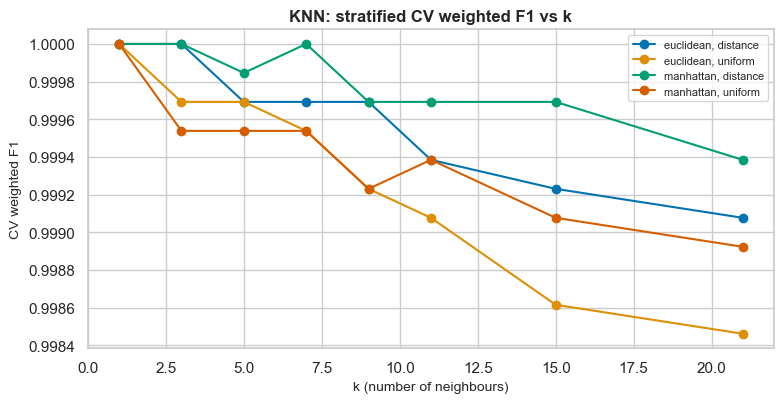

In [15]:
r = train("K-Nearest Neighbors")
res = pd.DataFrame(r["search"].cv_results_)
fig, ax = plt.subplots(figsize=(8, 4.2))
for (metric, weights), grp in res.groupby(["param_model__metric", "param_model__weights"]):
    ax.plot(grp["param_model__n_neighbors"].astype(int), grp["mean_test_score"], marker="o", label=f"{metric}, {weights}")
ax.set(title="KNN: stratified CV weighted F1 vs k", xlabel="k (number of neighbours)", ylabel="CV weighted F1"); ax.legend(fontsize=8)
fig.tight_layout(); save_fig(fig, TRACK, "knn_k_curve"); plt.show()

### Observation — KNN and distance metrics
- On pure 0/1 one-hot vectors, the **Manhattan** distance between two mushrooms is twice the number of attributes on which they differ (a Hamming-style count), and the **Euclidean** distance is the square root of that same count. The two would therefore rank neighbours identically. The curves above are close but not identical, because the single standardised numeric feature (`stalk_ring_asymmetry`) is not 0/1, and because distance weighting uses 1/d, which differs between the two metrics.
- CV F1 is highest at **k = 1** for every metric/weighting combination and falls slowly as k grows (to about 0.9985-0.9994 at k = 21), as larger neighbourhoods start to include mushrooms of other species. The search picked k = 1 (Euclidean, uniform), the first of several configurations tied at CV F1 = 1.000, because `GridSearchCV` breaks ties by grid order.
- k = 1 is the highest-variance setting: it memorises the training set. It works here only because the data is built from descriptions of 23 species, so most test mushrooms have a near-identical twin in the training set.

> ✍️ **DRAFT – rewrite in your own words.** The numbers come from the output above; the wording is AI-drafted and must be checked and rewritten by the team (guideline 7.5).

### 11.3 Gaussian Naive Bayes — the conditional-independence assumption

Best parameters (stratified 5-fold CV on train): {'var_smoothing': 0.0001} | best CV F1 = 0.99169


,Accuracy,Precision,Recall,F1 (weighted),ROC-AUC,Poisonous recall,Poisonous predicted edible
baseline (test),0.96985,0.97135,0.96985,0.96985,0.99626,0.99745,2.0
tuned (test),0.99323,0.99327,0.99323,0.99323,0.99922,0.99745,2.0
final model (train),0.99261,0.99272,0.99261,0.99262,0.99991,0.99968,1.0


Confusion matrix on test (rows = actual edible/poisonous, columns = predicted edible/poisonous):
[[833   9]
 [  2 781]]


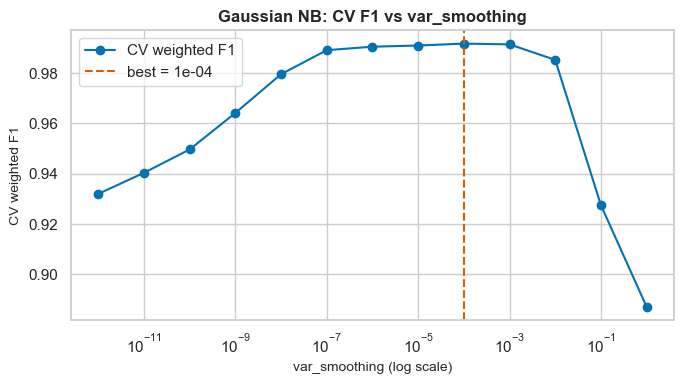

Cramer's V between stalk-surface-above-ring and -below-ring: 0.49
Cramer's V between stalk-color-above-ring and -below-ring  : 0.63


In [16]:
r = train("Gaussian Naive Bayes")
res = pd.DataFrame(r["search"].cv_results_)
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(res["param_model__var_smoothing"].astype(float), res["mean_test_score"], marker="o", label="CV weighted F1")
ax.axvline(r["best_params"]["var_smoothing"], color=sns.color_palette()[3], linestyle="--", label=f"best = {r['best_params']['var_smoothing']:.0e}")
ax.set(xscale="log", title="Gaussian NB: CV F1 vs var_smoothing", xlabel="var_smoothing (log scale)", ylabel="CV weighted F1"); ax.legend()
fig.tight_layout(); save_fig(fig, TRACK, "gaussian_nb_var_smoothing"); plt.show()
print(f"Cramer's V between stalk-surface-above-ring and -below-ring: {assoc.loc['stalk-surface-above-ring', 'stalk-surface-below-ring']:.2f}")
print(f"Cramer's V between stalk-color-above-ring and -below-ring  : {assoc.loc['stalk-color-above-ring', 'stalk-color-below-ring']:.2f}")

### Discussion — conditional independence
Naive Bayes assumes every feature is **independent of every other feature, given the class**. Under that assumption the likelihood factorises as $P(\mathbf{x}\mid y) = \prod_j P(x_j \mid y)$. Two problems apply here:
1. The assumption is clearly violated: the stalk pairs are strongly associated (see the Cramér's V values printed above), so NB counts the same evidence twice.
2. *Gaussian* NB models each 0/1 one-hot column as a normal distribution. For binary data this is a poor fit (Categorical or Bernoulli NB would match the data better), and it explains why `var_smoothing`, which adds variance to every feature, has such a large effect.

Even so, NB stays competitive, because classification only needs the *ranking* of class posteriors to be right, not the probabilities themselves. Measured: the default `var_smoothing = 1e-9` gives test F1 0.96985. CV selects `1e-4`, which raises test F1 to **0.99323**, but NB is still the weakest model, with 9 edible mushrooms called poisonous and **2 poisonous called edible**.

> ✍️ **DRAFT – rewrite in your own words.** The numbers come from the output above; the wording is AI-drafted and must be checked and rewritten by the team (guideline 7.5).

### 11.4 Decision Tree — tune `max_depth`, visualise the tree

Best parameters (stratified 5-fold CV on train): {'criterion': 'gini', 'max_depth': 5, 'min_samples_leaf': 1} | best CV F1 = 0.99969


,Accuracy,Precision,Recall,F1 (weighted),ROC-AUC,Poisonous recall,Poisonous predicted edible
baseline (test),1.00000,1.00000,1.00000,1.00000,1.00000,1.00000,0.0
tuned (test),0.99877,0.99877,0.99877,0.99877,0.99898,0.99745,2.0
final model (train),0.99985,0.99985,0.99985,0.99985,0.99987,0.99968,1.0


Confusion matrix on test (rows = actual edible/poisonous, columns = predicted edible/poisonous):
[[842   0]
 [  2 781]]


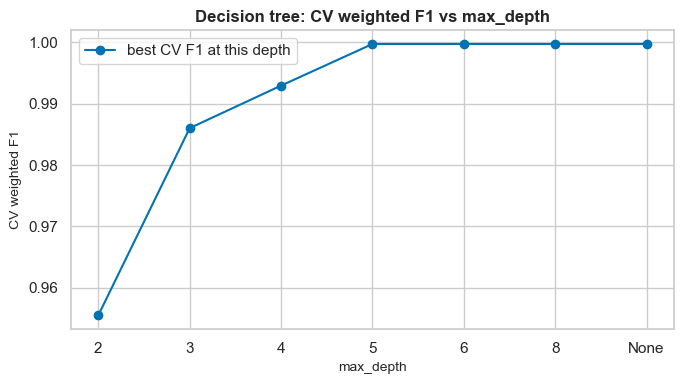

Tuned tree: depth = 5, leaves = 12


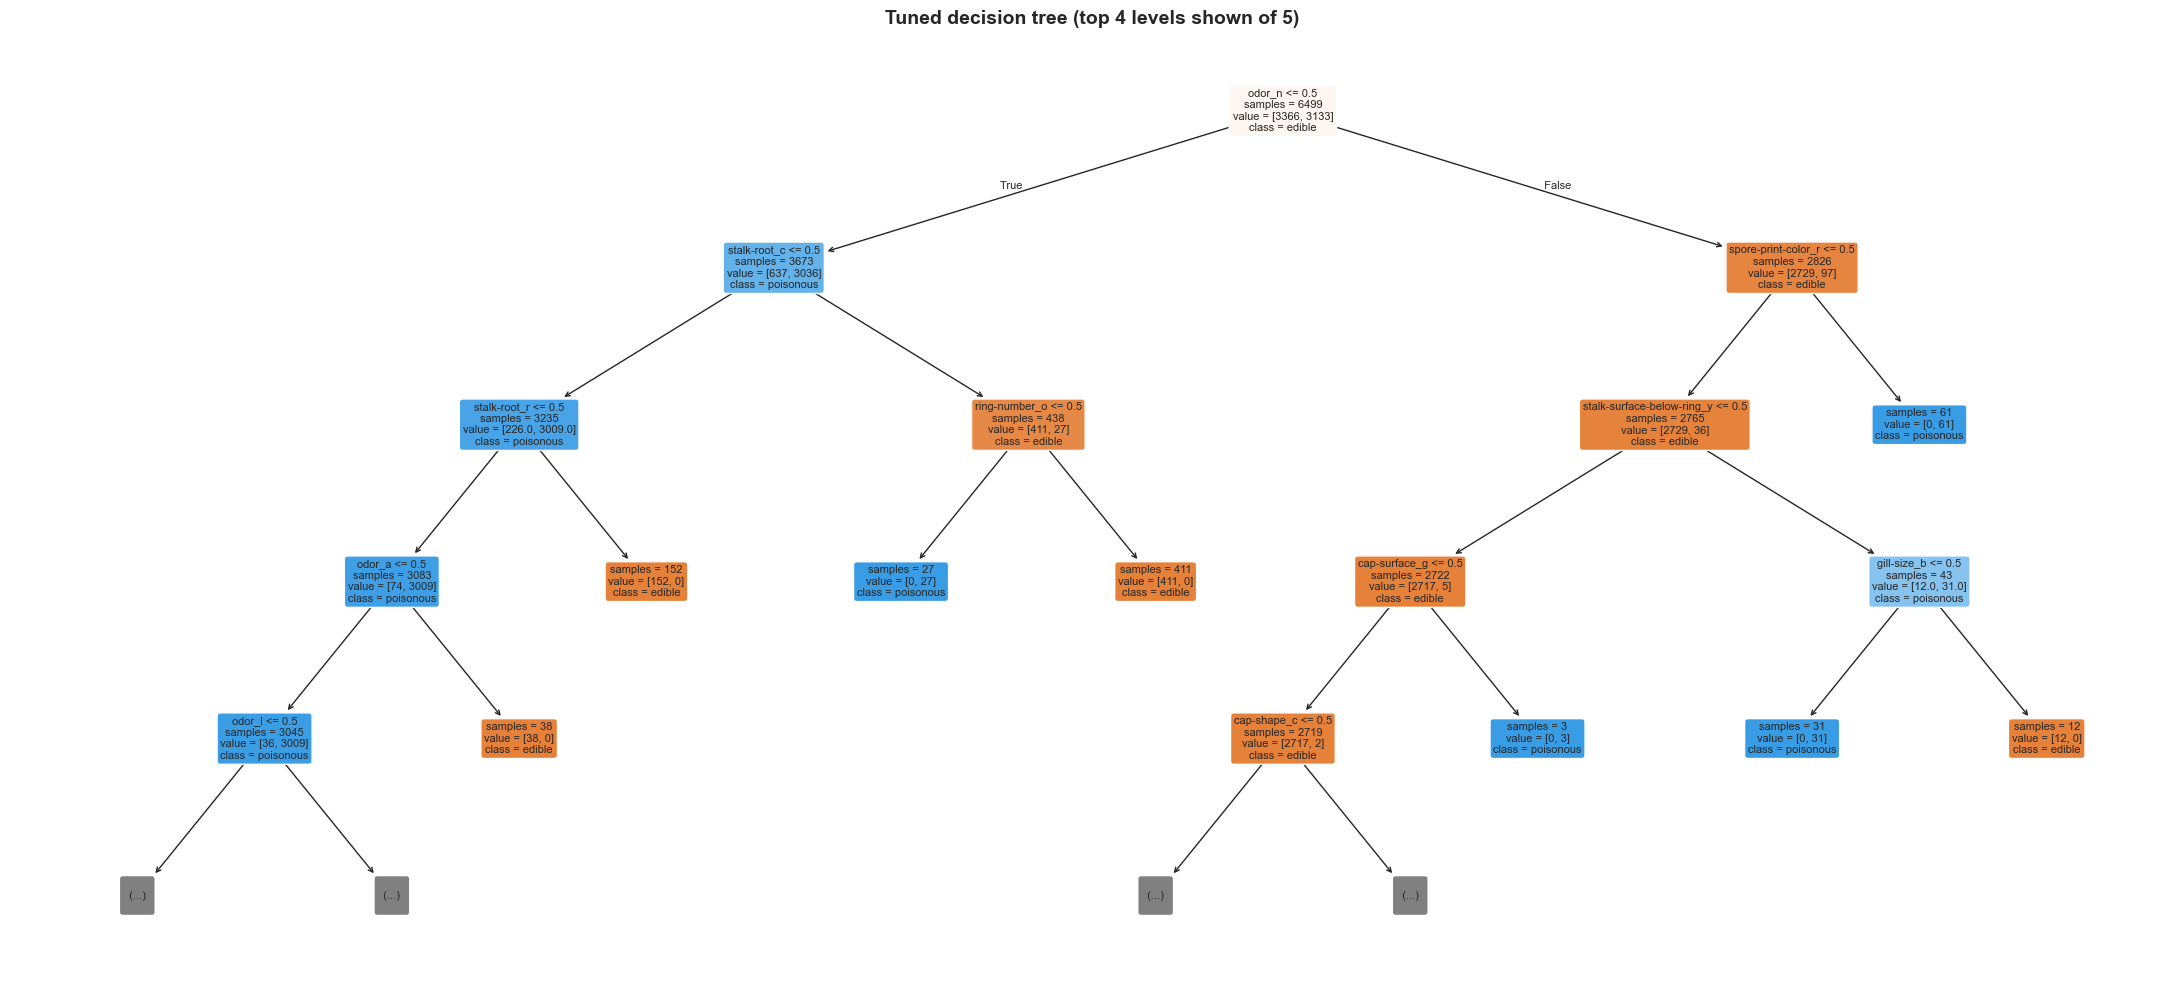

|--- odor_n <= 0.50
|   |--- stalk-root_c <= 0.50
|   |   |--- stalk-root_r <= 0.50
|   |   |   |--- odor_a <= 0.50
|   |   |   |   |--- truncated branch of depth 2
|   |   |   |--- odor_a >  0.50
|   |   |   |   |--- class: 0
|   |   |--- stalk-root_r >  0.50
|   |   |   |--- class: 0
|   |--- stalk-root_c >  0.50
|   |   |--- ring-number_o <= 0.50
|   |   |   |--- class: 1
|   |   |--- ring-number_o >  0.50
|   |   |   |--- class: 0
|--- odor_n >  0.50
|   |--- spore-print-color_r <= 0.50
|   |   |--- stalk-surface-below-ring_y <= 0.50
|   |   |   |--- cap-surface_g <= 0.50
|   |   |   |   |--- truncated branch of depth 2
|   |   |   |--- cap-surface_g >  0.50
|   |   |   |   |--- class: 1
|   |   |--- stalk-surface-below-ring_y >  0.50
|   |   |   |--- gill-size_b <= 0.50
|   |   |   |   |--- class: 1
|   |   |   |--- gill-size_b >  0.50
|   |   |   |   |--- class: 0
|   |--- spore-print-color_r >  0.50
|   |   |--- class: 1



In [17]:
r = train("Decision Tree")
res = pd.DataFrame(r["search"].cv_results_)
res["max_depth"] = res["param_model__max_depth"].astype(str)
depth_curve = res.groupby("max_depth")["mean_test_score"].max().reindex(["2", "3", "4", "5", "6", "8", "None"])
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(depth_curve.index, depth_curve.values, marker="o", label="best CV F1 at this depth")
ax.set(title="Decision tree: CV weighted F1 vs max_depth", xlabel="max_depth", ylabel="CV weighted F1"); ax.legend()
fig.tight_layout(); save_fig(fig, TRACK, "tree_depth_curve"); plt.show()

tree = r["final_model"].named_steps["model"]
print(f"Tuned tree: depth = {tree.get_depth()}, leaves = {tree.get_n_leaves()}")
short_names = [n.replace("cat__", "").replace("num__", "") for n in feature_names]
fig, ax = plt.subplots(figsize=(22, 10))
plot_tree(tree, feature_names=short_names, class_names=["edible", "poisonous"], filled=True, rounded=True,
          max_depth=4, fontsize=8, impurity=False, proportion=False, ax=ax)
ax.set_title(f"Tuned decision tree (top {min(4, tree.get_depth())} levels shown of {tree.get_depth()})", fontsize=14, fontweight="bold")
fig.tight_layout(); save_fig(fig, TRACK, "decision_tree_plot"); plt.show()
print(export_text(tree, feature_names=short_names, max_depth=3))

### Observation — the tree
- The root split is `odor = n` (no odour), matching the EDA finding that odour is the most informative feature. Mushrooms *with* an odour are separated mainly by stalk-root and further odour levels; odourless ones mainly by `spore-print-color = r` (green, which leads to poisonous).
- The tuned tree has depth 5 and 12 leaves, and it makes **2 poisonous-as-edible errors** on the test set. The unrestricted baseline tree was perfect. Several depths tied at the best CV F1 (0.99969), and `GridSearchCV` chooses the first tied configuration, i.e. the shallower tree. **Tuning by cross-validation does not guarantee a better test score.** We report the drop rather than hide it.

> ✍️ **DRAFT – rewrite in your own words.** The numbers come from the output above; the wording is AI-drafted and must be checked and rewritten by the team (guideline 7.5).

### 11.5 Support Vector Machine (SVC) — tune `C` and `kernel`

In [18]:
r = train("Support Vector Machine (SVC)")
res = pd.DataFrame(r["search"].cv_results_)
display(res.pivot_table(index="param_model__C", columns="param_model__kernel", values="mean_test_score").round(5))
print("Support vectors per class (e, p):", r["final_model"].named_steps["model"].n_support_)

Best parameters (stratified 5-fold CV on train): {'C': 1, 'kernel': 'linear'} | best CV F1 = 1.00000


,Accuracy,Precision,Recall,F1 (weighted),ROC-AUC,Poisonous recall,Poisonous predicted edible
baseline (test),1.0,1.0,1.0,1.0,1.0,1.0,0.0
tuned (test),1.0,1.0,1.0,1.0,1.0,1.0,0.0
final model (train),1.0,1.0,1.0,1.0,1.0,1.0,0.0


Confusion matrix on test (rows = actual edible/poisonous, columns = predicted edible/poisonous):
[[842   0]
 [  0 783]]


param_model__kernel,linear,rbf
param_model__C,,
0.01,0.99215,0.93684
0.10,0.99923,0.99846
1.00,1.00000,0.99938
10.00,1.00000,1.00000


Support vectors per class (e, p): [133 113]


**Scaling for SVC.** The RBF kernel $\exp(-\gamma\lVert x - x'\rVert^2)$ and the margin are both defined by distances, so every input must be on a comparable scale. Here the one-hot columns are 0/1 and the engineered feature is standardised inside the pipeline, which is what the requirement to "scale features" means for this dataset.

### 11.6 Part A preliminary comparison (Review 1, D2)

In [19]:
part_a = list(specs)[:5]
prelim = pd.DataFrame({n: runs[n]["final_test"] for n in part_a}).T[["Accuracy", "F1 (weighted)", "Poisonous predicted edible"]]
display(prelim.sort_values("F1 (weighted)", ascending=False).round(5))

,Accuracy,F1 (weighted),Poisonous predicted edible
Logistic Regression,1.00000,1.00000,0.0
K-Nearest Neighbors,1.00000,1.00000,0.0
Support Vector Machine (SVC),1.00000,1.00000,0.0
Decision Tree,0.99877,0.99877,2.0
Gaussian Naive Bayes,0.99323,0.99323,2.0


## 12. Classification Part B (Review 2, A1)
### 12.1 Random Forest — tune `n_estimators`, feature importance

Best parameters (stratified 5-fold CV on train): {'max_depth': None, 'max_features': 'sqrt', 'n_estimators': 25} | best CV F1 = 1.00000


,Accuracy,Precision,Recall,F1 (weighted),ROC-AUC,Poisonous recall,Poisonous predicted edible
baseline (test),1.0,1.0,1.0,1.0,1.0,1.0,0.0
tuned (test),1.0,1.0,1.0,1.0,1.0,1.0,0.0
final model (train),1.0,1.0,1.0,1.0,1.0,1.0,0.0


Confusion matrix on test (rows = actual edible/poisonous, columns = predicted edible/poisonous):
[[842   0]
 [  0 783]]


,max_depth,max_features,n_estimators,mean_test_score,std_test_score
0,None,sqrt,25,1.0,0.0
21,10,log2,50,1.0,0.0
19,10,sqrt,200,1.0,0.0
18,10,sqrt,100,1.0,0.0
17,10,sqrt,50,1.0,0.0
16,10,sqrt,25,1.0,0.0


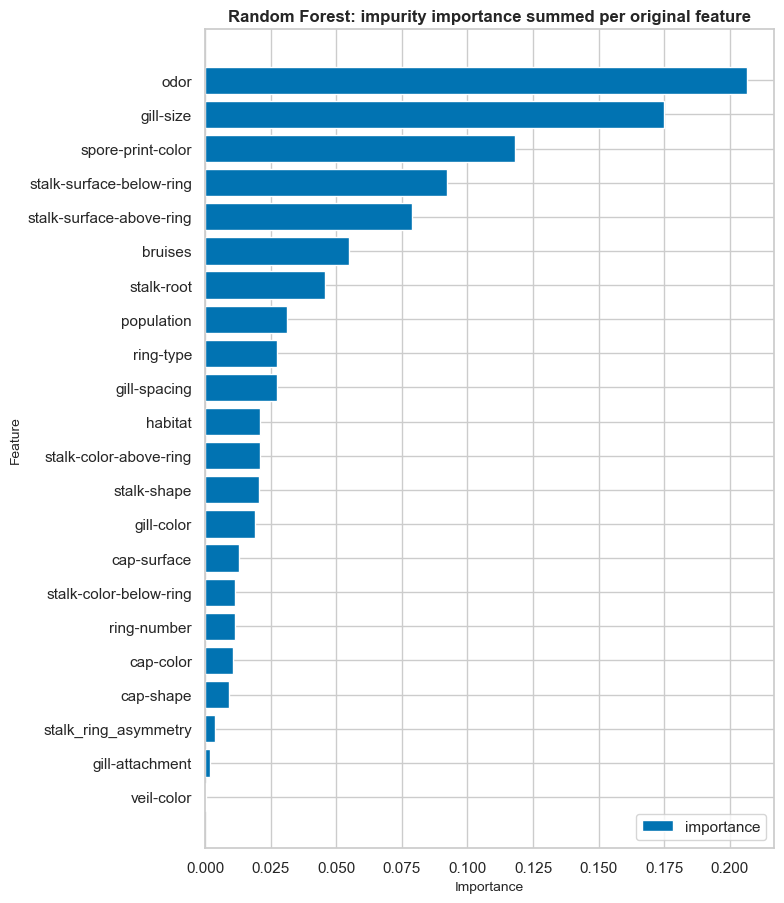

In [20]:
r = train("Random Forest")
display(cv_table(r, top=6).round(5))

def importance_by_feature(model_importances):
    """Sum one-hot importances back to their original column for readability."""
    s = pd.Series(model_importances, index=feature_names)
    groups = [n[5:] if n.startswith("num__") else n[5:].rsplit("_", 1)[0] for n in feature_names]
    return s.groupby(groups).sum().sort_values(ascending=False)

rf_imp = importance_by_feature(r["final_model"].named_steps["model"].feature_importances_)
fig = plot_feature_importance(rf_imp.index, rf_imp.values, "Random Forest: impurity importance summed per original feature", top_n=22)
save_fig(fig, TRACK, "random_forest_feature_importance"); plt.show()

### 12.2 AdaBoost — tune `n_estimators` and `learning_rate`

In [21]:
r = train("AdaBoost")
res = pd.DataFrame(r["search"].cv_results_)
display(res.pivot_table(index="param_model__n_estimators", columns="param_model__learning_rate", values="mean_test_score").round(5))

Best parameters (stratified 5-fold CV on train): {'learning_rate': 1.0, 'n_estimators': 200} | best CV F1 = 0.99969


,Accuracy,Precision,Recall,F1 (weighted),ROC-AUC,Poisonous recall,Poisonous predicted edible
baseline (test),0.99815,0.99816,0.99815,0.99815,1.0,0.99617,3.0
tuned (test),1.00000,1.00000,1.00000,1.00000,1.0,1.00000,0.0
final model (train),1.00000,1.00000,1.00000,1.00000,1.0,1.00000,0.0


Confusion matrix on test (rows = actual edible/poisonous, columns = predicted edible/poisonous):
[[842   0]
 [  0 783]]


param_model__learning_rate,0.1,0.5,1.0
param_model__n_estimators,,,
25,0.97369,0.97968,0.99523
50,0.96706,0.99846,0.99908
100,0.97184,0.99846,0.99938
200,0.98199,0.99923,0.99969


### 12.3 Gradient Boosting Classifier (scikit-learn GBM)

In [22]:
r = train("Gradient Boosting")
display(cv_table(r, top=6).round(5))

Best parameters (stratified 5-fold CV on train): {'learning_rate': 0.05, 'max_depth': 3, 'n_estimators': 100} | best CV F1 = 0.99969


,Accuracy,Precision,Recall,F1 (weighted),ROC-AUC,Poisonous recall,Poisonous predicted edible
baseline (test),0.99877,0.99877,0.99877,0.99877,1.00000,0.99745,2.0
tuned (test),0.99877,0.99877,0.99877,0.99877,0.99990,0.99745,2.0
final model (train),0.99985,0.99985,0.99985,0.99985,0.99999,0.99968,1.0


Confusion matrix on test (rows = actual edible/poisonous, columns = predicted edible/poisonous):
[[842   0]
 [  2 781]]


,learning_rate,max_depth,n_estimators,mean_test_score,std_test_score
8,0.1,2,200,0.99969,0.00062
15,0.2,3,50,0.99969,0.00062
14,0.2,2,200,0.99969,0.00062
13,0.2,2,100,0.99969,0.00062
11,0.1,3,200,0.99969,0.00062
10,0.1,3,100,0.99969,0.00062


### 12.4 Bagging Classifier with a Decision Tree base estimator

In [23]:
r = train("Bagging (Decision Tree)")
bag = r["final_model"].named_steps["model"]
print("Base estimator:", bag.estimator, "| number of trees:", len(bag.estimators_))
display(cv_table(r, top=6).round(5))

Best parameters (stratified 5-fold CV on train): {'max_features': 0.5, 'max_samples': 0.5, 'n_estimators': 25} | best CV F1 = 1.00000


,Accuracy,Precision,Recall,F1 (weighted),ROC-AUC,Poisonous recall,Poisonous predicted edible
baseline (test),0.99877,0.99877,0.99877,0.99877,1.0,0.99745,2.0
tuned (test),1.00000,1.00000,1.00000,1.00000,1.0,1.00000,0.0
final model (train),1.00000,1.00000,1.00000,1.00000,1.0,1.00000,0.0


Confusion matrix on test (rows = actual edible/poisonous, columns = predicted edible/poisonous):
[[842   0]
 [  0 783]]
Base estimator: DecisionTreeClassifier(random_state=42) | number of trees: 25


,max_features,max_samples,n_estimators,mean_test_score,std_test_score
1,0.5,0.5,25,1.00000,0.00000
4,0.5,1.0,10,1.00000,0.00000
5,0.5,1.0,25,1.00000,0.00000
6,0.5,1.0,50,1.00000,0.00000
7,0.5,1.0,100,1.00000,0.00000
0,0.5,0.5,10,0.99969,0.00062


### 12.5 MLP Classifier (neural network) — tune `hidden_layer_sizes` and `activation`, check convergence

Best parameters (stratified 5-fold CV on train): {'activation': 'relu', 'alpha': 0.0001, 'hidden_layer_sizes': (64, 32)} | best CV F1 = 1.00000


,Accuracy,Precision,Recall,F1 (weighted),ROC-AUC,Poisonous recall,Poisonous predicted edible
baseline (test),1.0,1.0,1.0,1.0,1.0,1.0,0.0
tuned (test),1.0,1.0,1.0,1.0,1.0,1.0,0.0
final model (train),1.0,1.0,1.0,1.0,1.0,1.0,0.0


Confusion matrix on test (rows = actual edible/poisonous, columns = predicted edible/poisonous):
[[842   0]
 [  0 783]]


,activation,alpha,hidden_layer_sizes,mean_test_score,std_test_score
2,relu,0.0001,"(64, 32)",1.00000,0.00000
5,relu,0.0100,"(64, 32)",1.00000,0.00000
8,tanh,0.0001,"(64, 32)",0.99985,0.00031
14,logistic,0.0001,"(64, 32)",0.99985,0.00031
11,tanh,0.0100,"(64, 32)",0.99985,0.00031
15,logistic,0.0100,"(16,)",0.99969,0.00062
13,logistic,0.0001,"(64,)",0.99969,0.00062
12,logistic,0.0001,"(16,)",0.99969,0.00062


Final MLP: layers (64, 32), activation relu, stopped after 23 of max_iter=1000 epochs
ConvergenceWarnings raised while fitting in this process: 0


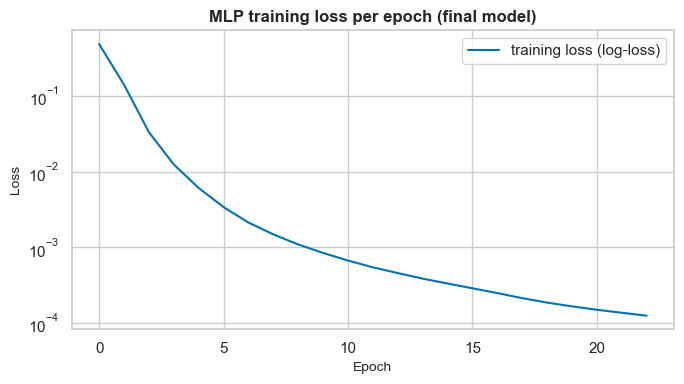

In [24]:
with warnings.catch_warnings(record=True) as caught:
    warnings.simplefilter("always", ConvergenceWarning)
    r = train("MLP Neural Network")
display(cv_table(r, top=8).round(5))
mlp = r["final_model"].named_steps["model"]
conv = [w for w in caught if issubclass(w.category, ConvergenceWarning)]
print(f"Final MLP: layers {mlp.hidden_layer_sizes}, activation {mlp.activation}, stopped after {mlp.n_iter_} of max_iter={mlp.max_iter} epochs")
print(f"ConvergenceWarnings raised while fitting in this process: {len(conv)}")
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(mlp.loss_curve_, label="training loss (log-loss)")
ax.set(title="MLP training loss per epoch (final model)", xlabel="Epoch", ylabel="Loss", yscale="log"); ax.legend()
fig.tight_layout(); save_fig(fig, TRACK, "mlp_loss_curve"); plt.show()

### Observation — Part B ensembles and the MLP
- **Random Forest** (25 trees, `max_features = sqrt`) is perfect on test. Its importance ranking, summed back to the original columns, puts `odor` first, then `gill-size`, `spore-print-color` and the stalk-surface pair. Our engineered `stalk_ring_asymmetry` ranks near the bottom, because the forest can already represent it through combinations of the stalk columns.
- **AdaBoost** benefited most from tuning among Part B: the baseline (50 stumps) made 3 poisonous-as-edible errors, and with 200 estimators it makes 0.
- **Bagging** improved from F1 0.99877 to 1.0 once each tree saw only 50% of the rows *and* 50% of the features. Feature subsampling decorrelates the trees, which is the same idea that Random Forest builds in.
- **Gradient Boosting** makes 2 poisonous-as-edible errors both before and after tuning.
- The **MLP** (64 -> 32 ReLU units) converged in 23 epochs, far below `max_iter = 1000`, and raised no `ConvergenceWarning`. The loss curve falls smoothly.

> ✍️ **DRAFT – rewrite in your own words.** The numbers come from the output above; the wording is AI-drafted and must be checked and rewritten by the team (guideline 7.5).

## 13. Consolidated comparison of all ten classifiers (Review 2, A2)

Every tuned model is scored on the **same stratified test set of 1,625 mushrooms**. They are ranked by weighted F1, then ROC-AUC, then fewest poisonous-predicted-edible errors.

In [25]:
rows = []
for i, (name, r) in enumerate(runs.items()):
    t = r["final_test"]
    rows.append({"Model": name, "Part": "A" if i < 5 else "B",
                 "Accuracy": t["Accuracy"], "Precision": t["Precision"], "Recall": t["Recall"],
                 "F1 (weighted)": t["F1 (weighted)"], "ROC-AUC": t["ROC-AUC"],
                 "Poisonous recall": t["Poisonous recall"], "Poisonous predicted edible": t["Poisonous predicted edible"],
                 "Train accuracy": r["final_train"]["Accuracy"], "CV F1 (5-fold, train)": r.get("best_cv_score", np.nan),
                 "Baseline test F1": r["baseline_test"]["F1 (weighted)"], "Best params": r.get("best_params", {}),
                 "Fit time (s)": r["final_fit_seconds"], "Latency (ms / 1k rows)": r["latency_ms_per_1k"], "Size (MB)": r["size_mb"]})
comparison = (pd.DataFrame(rows)
              .sort_values(["F1 (weighted)", "ROC-AUC", "Poisonous predicted edible"], ascending=[False, False, True])
              .reset_index(drop=True))
comparison.index = comparison.index + 1
comparison.index.name = "Rank"
comparison.to_csv(config.RESULTS_DIR / "classification_results.csv")
display(comparison.drop(columns=["Best params"]).round(5))

,Model,Part,Accuracy,Precision,Recall,F1 (weighted),ROC-AUC,Poisonous recall,Poisonous predicted edible,Train accuracy,"CV F1 (5-fold, train)",Baseline test F1,Fit time (s),Latency (ms / 1k rows),Size (MB)
Rank,,,,,,,,,,,,,,,
1,Logistic Regression,A,1.00000,1.00000,1.00000,1.00000,1.00000,1.00000,0,1.00000,0.99985,0.99938,0.04415,5.75735,0.00556
2,K-Nearest Neighbors,A,1.00000,1.00000,1.00000,1.00000,1.00000,1.00000,0,1.00000,1.00000,1.00000,0.05322,22.01858,5.85548
3,Support Vector Machine (SVC),A,1.00000,1.00000,1.00000,1.00000,1.00000,1.00000,0,1.00000,1.00000,1.00000,0.58013,14.01822,0.22952
4,Random Forest,B,1.00000,1.00000,1.00000,1.00000,1.00000,1.00000,0,1.00000,1.00000,1.00000,0.07801,15.84683,0.12457
5,AdaBoost,B,1.00000,1.00000,1.00000,1.00000,1.00000,1.00000,0,1.00000,0.99969,0.99815,1.28025,26.54751,0.12916
6,Bagging (Decision Tree),B,1.00000,1.00000,1.00000,1.00000,1.00000,1.00000,0,1.00000,1.00000,0.99877,0.19354,90.01729,0.09472
7,MLP Neural Network,B,1.00000,1.00000,1.00000,1.00000,1.00000,1.00000,0,1.00000,1.00000,1.00000,0.49218,7.80511,0.30683
8,Gradient Boosting,B,0.99877,0.99877,0.99877,0.99877,0.99990,0.99745,2,0.99985,0.99969,0.99877,0.94819,5.94326,0.13729
9,Decision Tree,A,0.99877,0.99877,0.99877,0.99877,0.99898,0.99745,2,0.99985,0.99969,1.00000,0.04646,5.13452,0.00686


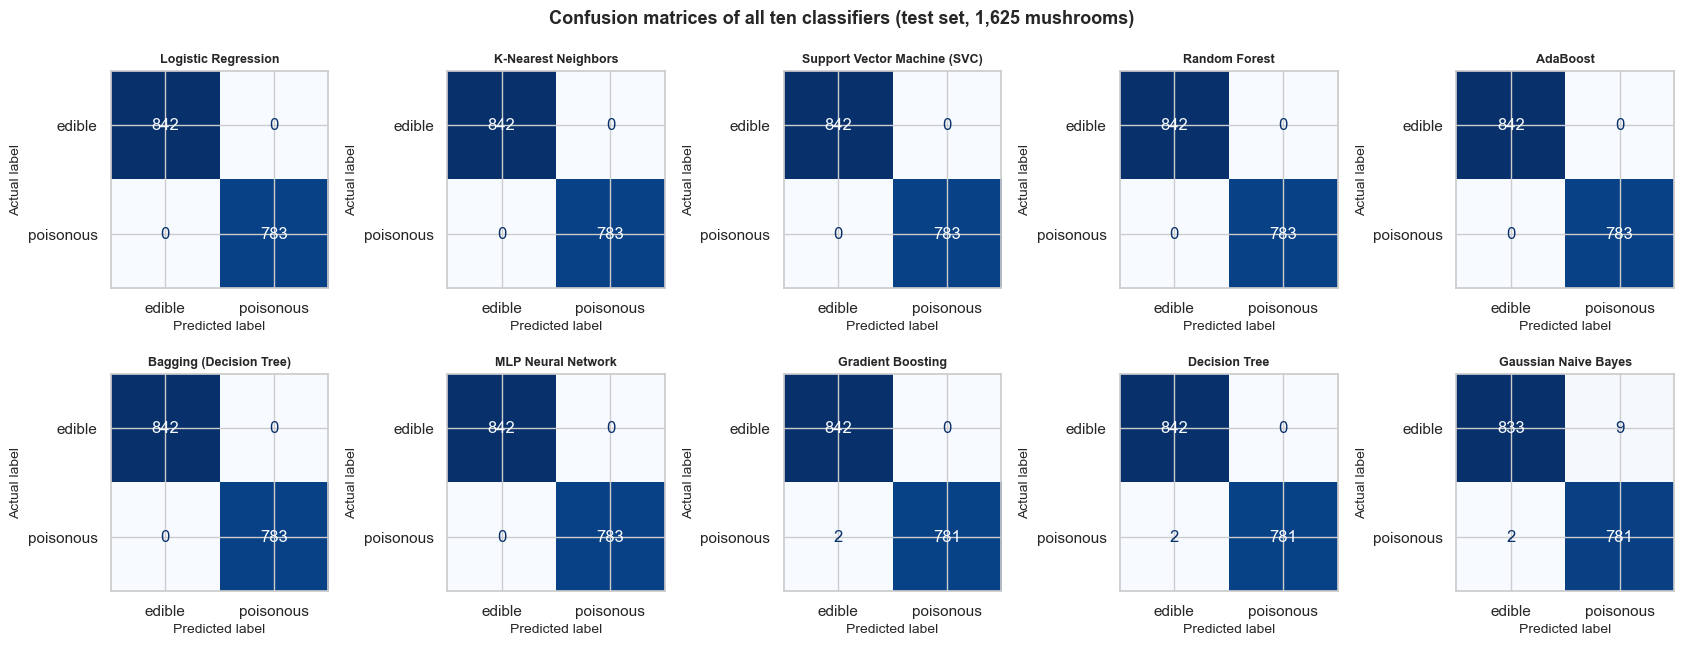

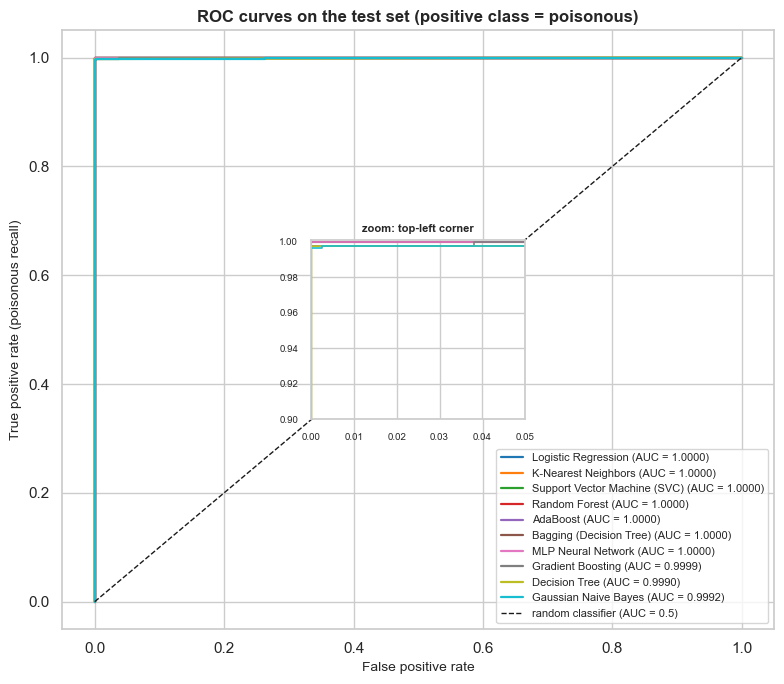

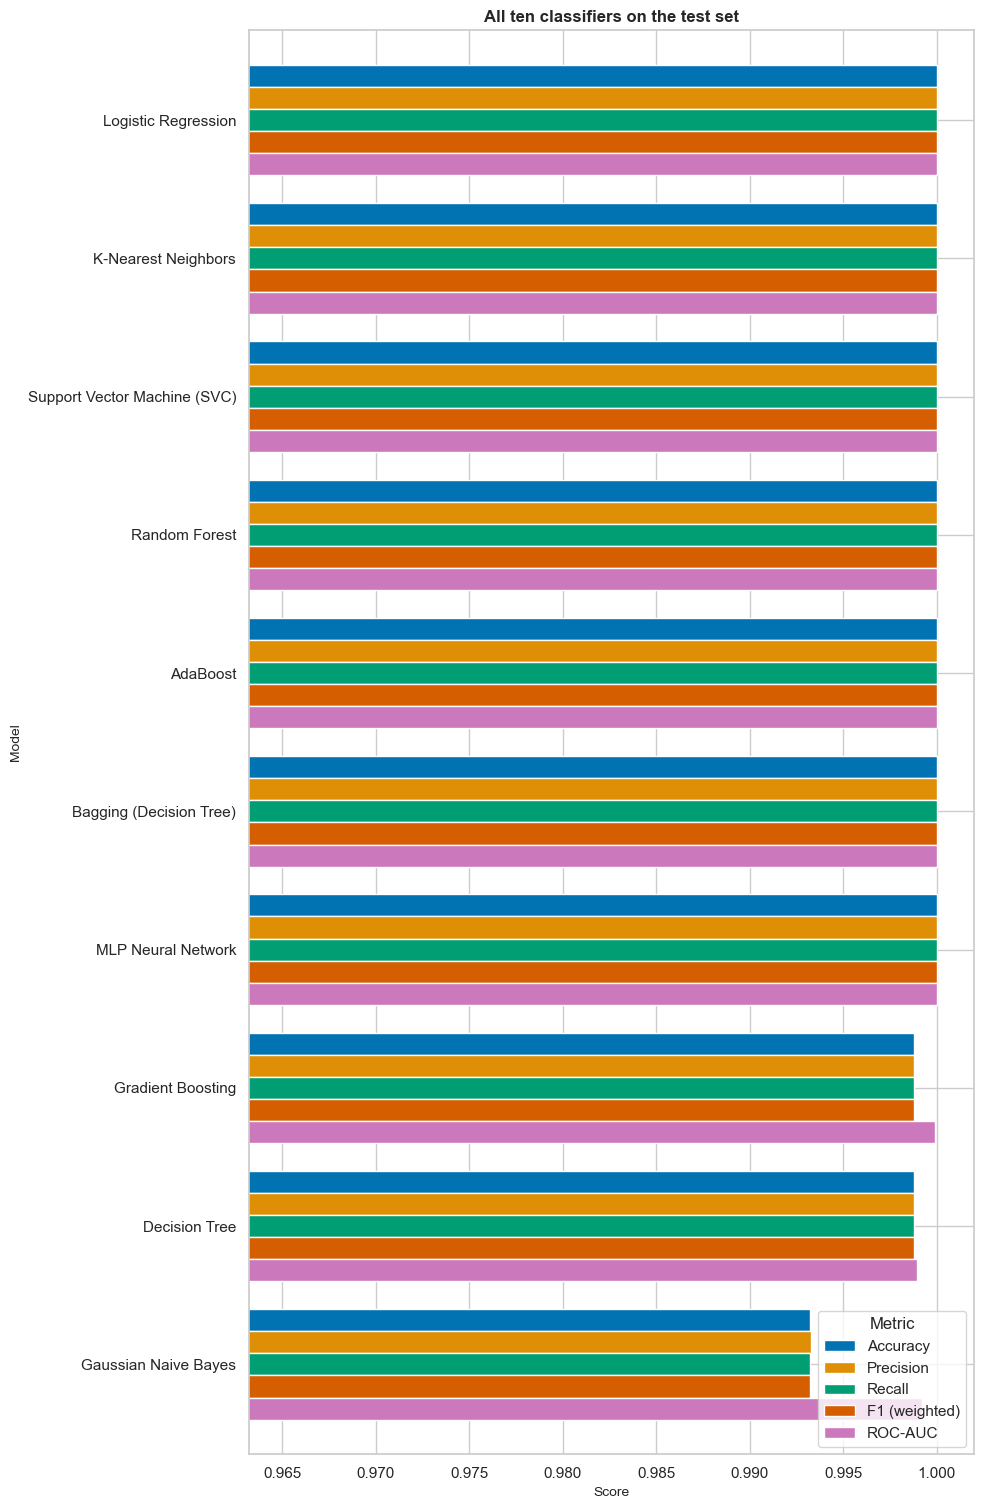

In [26]:
fig = plot_confusion_grid({n: runs[n]["confusion"] for n in comparison["Model"]}, ["edible", "poisonous"],
                          title="Confusion matrices of all ten classifiers (test set, 1,625 mushrooms)")
save_fig(fig, TRACK, "confusion_matrices_all"); plt.show()

fig, ax = plt.subplots(figsize=(8, 7))
for i, name in enumerate(comparison["Model"]):
    scores, _ = score_for_roc(runs[name]["final_model"], X_test)
    fpr, tpr, _ = roc_curve(y_test == POS, scores[:, 1])
    ax.plot(fpr, tpr, color=sns.color_palette("tab10")[i], linewidth=1.6, label=f"{name} (AUC = {runs[name]['final_test']['ROC-AUC']:.4f})")
ax.plot([0, 1], [0, 1], "k--", linewidth=1, label="random classifier (AUC = 0.5)")
ax.set(title="ROC curves on the test set (positive class = poisonous)", xlabel="False positive rate", ylabel="True positive rate (poisonous recall)")
ax.legend(fontsize=8, loc="lower right")
inset = ax.inset_axes([0.35, 0.35, 0.3, 0.3])
for i, name in enumerate(comparison["Model"]):
    scores, _ = score_for_roc(runs[name]["final_model"], X_test)
    fpr, tpr, _ = roc_curve(y_test == POS, scores[:, 1])
    inset.plot(fpr, tpr, color=sns.color_palette("tab10")[i], linewidth=1.2)
inset.set(xlim=(0, 0.05), ylim=(0.9, 1.001), title="zoom: top-left corner"); inset.title.set_fontsize(8); inset.tick_params(labelsize=7)
fig.tight_layout(); save_fig(fig, TRACK, "roc_curves_all"); plt.show()

fig = plot_metric_bars(comparison, ["Accuracy", "Precision", "Recall", "F1 (weighted)", "ROC-AUC"],
                       "All ten classifiers on the test set", xlim=(max(0.0, comparison["Accuracy"].min() - 0.03), 1.002))
save_fig(fig, TRACK, "model_comparison_metrics"); plt.show()

### Observation — comparison
- **Seven of ten models classify all 1,625 test mushrooms correctly:** Logistic Regression, KNN, SVC, Random Forest, AdaBoost, Bagging and the MLP. Each has Accuracy = Precision = Recall = F1 = ROC-AUC = 1.000.
- Gradient Boosting and the tuned Decision Tree each make **2 poisonous-as-edible errors** (F1 0.99877). Gaussian NB is lowest (F1 0.99323; 11 errors, 2 of them dangerous).
- **ROC-AUC is at or above 0.999 for every model**, so every model ranks almost all poisonous mushrooms above almost all edible ones. The differences lie in where the decision threshold falls.
- Because the test set cannot separate the top seven, model choice has to rest on **CV stability and practical cost**. Sizes range from about 0.006 MB (Logistic Regression) to 5.9 MB (KNN, which stores the whole training set), and Logistic Regression has the lowest prediction latency.

> ✍️ **DRAFT – rewrite in your own words.** The numbers come from the output above; the wording is AI-drafted and must be checked and rewritten by the team (guideline 7.5).

## 14. Hyperparameter tuning summary

In [27]:
tuning = []
for name, r in runs.items():
    tuning.append({"Model": name, "Configs tried": len(r["search"].cv_results_["params"]), "Best params": r["best_params"],
                   "Best CV F1": r["best_cv_score"],
                   "Baseline test F1": r["baseline_test"]["F1 (weighted)"], "Tuned test F1": r["tuned_test"]["F1 (weighted)"],
                   "F1 change": r["tuned_test"]["F1 (weighted)"] - r["baseline_test"]["F1 (weighted)"],
                   "Baseline poisonous->edible": r["baseline_test"]["Poisonous predicted edible"],
                   "Tuned poisonous->edible": r["tuned_test"]["Poisonous predicted edible"]})
tuning = pd.DataFrame(tuning).sort_values("F1 change", ascending=False).reset_index(drop=True)
display(tuning.round(5))
hp_path = config.RESULTS_DIR / "hyperparameter_results.json"
hp = load_json(hp_path) if hp_path.exists() else {}
hp["classification"] = {row["Model"]: {k: row[k] for k in tuning.columns if k != "Model"} for _, row in tuning.iterrows()}
save_json(hp, hp_path)

,Model,Configs tried,Best params,Best CV F1,Baseline test F1,Tuned test F1,F1 change,Baseline poisonous->edible,Tuned poisonous->edible
0,Gaussian Naive Bayes,13,{'var_smoothing': 0.0001},0.99169,0.96985,0.99323,0.02338,2,2
1,AdaBoost,12,"{'learning_rate': 1.0, 'n_estimators': 200}",0.99969,0.99815,1.00000,0.00185,3,0
2,Bagging (Decision Tree),16,"{'max_features': 0.5, 'max_samples': 0.5, 'n_estimators': 25}",1.00000,0.99877,1.00000,0.00123,2,0
3,Logistic Regression,6,{'C': 100},0.99985,0.99938,1.00000,0.00062,1,0
4,K-Nearest Neighbors,32,"{'metric': 'euclidean', 'n_neighbors': 1, 'weights': 'uniform'}",1.00000,1.00000,1.00000,0.00000,0,0
5,Support Vector Machine (SVC),8,"{'C': 1, 'kernel': 'linear'}",1.00000,1.00000,1.00000,0.00000,0,0
6,Random Forest,24,"{'max_depth': None, 'max_features': 'sqrt', 'n_estimators': 25}",1.00000,1.00000,1.00000,0.00000,0,0
7,Gradient Boosting,18,"{'learning_rate': 0.05, 'max_depth': 3, 'n_estimators': 100}",0.99969,0.99877,0.99877,0.00000,2,2
8,MLP Neural Network,18,"{'activation': 'relu', 'alpha': 0.0001, 'hidden_layer_sizes': (64,...",1.00000,1.00000,1.00000,0.00000,0,0
9,Decision Tree,42,"{'criterion': 'gini', 'max_depth': 5, 'min_samples_leaf': 1}",0.99969,1.00000,0.99877,-0.00123,0,2


WindowsPath('C:/Users/HP/Claude_Code/Coding/ML/reports/results/hyperparameter_results.json')

## 15. Stratified 5-fold cross-validation of the best models

Guideline 7.2 requires CV for at least the two best models. With several models tied at the top of the test ranking, **every model that ties the best test F1, plus the next one**, is cross-validated: stratified 5-fold on the training set, scoring weighted F1, accuracy, ROC-AUC and log-loss. Log-loss measures how confident and how well-calibrated the predicted probabilities are, which separates models that all classify perfectly.

In [28]:
best_f1 = comparison["F1 (weighted)"].max()
n_top = max(2, int((comparison["F1 (weighted)"] == best_f1).sum()) + 1)
cv_candidates = comparison["Model"].head(n_top).tolist()
cv_rows, cv_store = [], {}
for name in cv_candidates:
    res = sk_cross_validate(runs[name]["final_model"], X_train, y_train, cv=stratified_kfold(), n_jobs=-1,
                            scoring={"f1": "f1_weighted", "accuracy": "accuracy", "roc_auc": "roc_auc", "log_loss": "neg_log_loss"})
    cv_store[name] = {k.replace("test_", ""): res[k].tolist() for k in res if k.startswith("test_")}
    cv_rows.append({"Model": name, "CV F1 mean": res["test_f1"].mean(), "CV F1 std": res["test_f1"].std(),
                    "CV accuracy": res["test_accuracy"].mean(), "CV ROC-AUC": res["test_roc_auc"].mean(),
                    "CV log-loss": -res["test_log_loss"].mean(),
                    "Latency (ms / 1k rows)": runs[name]["latency_ms_per_1k"], "Size (MB)": runs[name]["size_mb"]})
cv_summary = pd.DataFrame(cv_rows)
display(cv_summary.round(6))
save_json(cv_store, config.RESULTS_DIR / "classification_cv.json")

,Model,CV F1 mean,CV F1 std,CV accuracy,CV ROC-AUC,CV log-loss,Latency (ms / 1k rows),Size (MB)
0,Logistic Regression,0.999846,0.000308,0.999846,1.000000,0.000631,5.757354,0.005556
1,K-Nearest Neighbors,1.000000,0.000000,1.000000,1.000000,0.000000,22.018585,5.855476
2,Support Vector Machine (SVC),1.000000,0.000000,1.000000,1.000000,0.000513,14.018215,0.229523
3,Random Forest,1.000000,0.000000,1.000000,1.000000,0.000677,15.846831,0.124574
4,AdaBoost,0.999692,0.000615,0.999692,1.000000,0.509561,26.547508,0.129161
5,Bagging (Decision Tree),1.000000,0.000000,1.000000,1.000000,0.001835,90.017292,0.094721
6,MLP Neural Network,1.000000,0.000000,1.000000,1.000000,0.000270,7.805108,0.306828
7,Gradient Boosting,0.999692,0.000615,0.999692,0.999837,0.008238,5.943262,0.137288


WindowsPath('C:/Users/HP/Claude_Code/Coding/ML/reports/results/classification_cv.json')

## 16. Final model selection (Review 2, A3)

**Selection rule, applied in order:**
1. **Safety:** no poisonous mushroom predicted as edible on the test set.
2. Highest weighted F1 on the test set (the rubric's main metric).
3. Mean stratified-CV F1 on the training set. Models whose CV mean is within **one CV standard deviation** of the best are treated as **tied**, because differences that small are within resampling noise. Here one standard deviation is about one misclassified mushroom out of 6,499.
4. Among tied models, choose the **simplest**: the smallest fitted model (fewest stored parameters). This is the same "prefer the simpler model when the evidence is tied" rule used in the regression notebook.

*Transparency note.* An earlier version of step 4 used CV log-loss as the tie-breaker, and it selected **1-nearest-neighbour**. 1-NN's predicted probabilities are always exactly 0 or 1, so when it makes no errors its log-loss is 0. That reflects over-confidence that log-loss cannot penalise without errors, not better calibration. 1-NN also memorises all 6,499 training rows. The tie-breaker was therefore replaced by the simplicity rule above. Both versions are shown below so the change can be checked.

In [29]:
sel = comparison[comparison["Model"].isin(cv_candidates)].merge(
    cv_summary[["Model", "CV F1 mean", "CV F1 std", "CV log-loss"]], on="Model")
safe = sel[(sel["Poisonous predicted edible"] == 0) & (sel["F1 (weighted)"] == sel["F1 (weighted)"].max())].copy()
leader = safe.loc[safe["CV F1 mean"].idxmax()]
safe["gap to best CV F1"] = leader["CV F1 mean"] - safe["CV F1 mean"]
safe["tied (gap <= 1 SD)"] = safe["gap to best CV F1"] <= np.maximum(safe["CV F1 std"], leader["CV F1 std"])
safe = safe.sort_values(["tied (gap <= 1 SD)", "Size (MB)"], ascending=[False, True])
display(safe[["Model", "F1 (weighted)", "CV F1 mean", "CV F1 std", "gap to best CV F1", "tied (gap <= 1 SD)",
              "Size (MB)", "Latency (ms / 1k rows)", "CV log-loss"]].round(6))
selected = safe.iloc[0]["Model"]
earlier_rule = safe.sort_values(["CV F1 mean", "CV log-loss"], ascending=[False, True]).iloc[0]["Model"]
best = runs[selected]["final_model"]
print(f"Selected model: {selected}  (smallest of the {int(safe['tied (gap <= 1 SD)'].sum())} statistically tied models)")
print(f"The earlier log-loss tie-breaker would have chosen: {earlier_rule}")

,Model,F1 (weighted),CV F1 mean,CV F1 std,gap to best CV F1,tied (gap <= 1 SD),Size (MB),Latency (ms / 1k rows),CV log-loss
0,Logistic Regression,1.0,0.999846,0.000308,0.000154,True,0.005556,5.757354,0.000631
5,Bagging (Decision Tree),1.0,1.000000,0.000000,0.000000,True,0.094721,90.017292,0.001835
3,Random Forest,1.0,1.000000,0.000000,0.000000,True,0.124574,15.846831,0.000677
4,AdaBoost,1.0,0.999692,0.000615,0.000308,True,0.129161,26.547508,0.509561
2,Support Vector Machine (SVC),1.0,1.000000,0.000000,0.000000,True,0.229523,14.018215,0.000513
6,MLP Neural Network,1.0,1.000000,0.000000,0.000000,True,0.306828,7.805108,0.000270
1,K-Nearest Neighbors,1.0,1.000000,0.000000,0.000000,True,5.855476,22.018585,0.000000


Selected model: Logistic Regression  (smallest of the 7 statistically tied models)
The earlier log-loss tie-breaker would have chosen: K-Nearest Neighbors


In [30]:
# Tuning effect on the SELECTED model: baseline (defaults) vs tuned, on the test set and in CV (log-loss included).
r = runs[selected]
before = sk_cross_validate(r["baseline_model"], X_train, y_train, cv=stratified_kfold(), scoring={"f1": "f1_weighted", "ll": "neg_log_loss"})
after = sk_cross_validate(r["final_model"], X_train, y_train, cv=stratified_kfold(), scoring={"f1": "f1_weighted", "ll": "neg_log_loss"})
sel_tuning = pd.DataFrame({
    "baseline (defaults)": {**r["baseline_test"], "CV F1 mean": before["test_f1"].mean(), "CV log-loss": -before["test_ll"].mean(),
                            "Test log-loss": log_loss(y_test, r["baseline_model"].predict_proba(X_test), labels=[0, 1])},
    f"tuned {r['best_params']}": {**r["tuned_test"], "CV F1 mean": after["test_f1"].mean(), "CV log-loss": -after["test_ll"].mean(),
                                  "Test log-loss": log_loss(y_test, r["final_model"].predict_proba(X_test), labels=[0, 1])},
}).T
display(sel_tuning.round(6))

,Accuracy,Precision,Recall,F1 (weighted),ROC-AUC,Poisonous recall,Poisonous predicted edible,CV F1 mean,CV log-loss,Test log-loss
baseline (defaults),0.999385,0.999385,0.999385,0.999385,1.0,0.998723,1.0,0.999385,0.007665,0.006774
tuned {'C': 100},1.000000,1.000000,1.000000,1.000000,1.0,1.000000,0.0,0.999846,0.000631,0.000612


### Observation — model selection and tuning
- Seven models are safe (0 poisonous-as-edible) with test F1 = 1.0, and all seven are **statistically tied** on CV F1. The largest gap from the best CV F1 is 0.0003, which is within one CV standard deviation (about one misclassified mushroom in 6,499).
- **Selected: Logistic Regression (C = 100).** It is the smallest model of the tied group (about 0.006 MB, against up to 5.9 MB for KNN), the fastest at prediction time, directly interpretable through odds ratios (§11.1), and it produces smooth probabilities that the app can display.
- **Tuning improved the selected model on every measure:** test F1 0.99938 → 1.000, poisonous-as-edible errors 1 → 0, CV F1 0.99938 → 0.99985, CV log-loss 0.0077 → 0.0006 and test log-loss 0.0068 → 0.0006. A larger C (weaker L2 penalty) lets the model use the near-separable structure fully.

> ✍️ **DRAFT – rewrite in your own words.** The numbers come from the output above; the wording is AI-drafted and must be checked and rewritten by the team (guideline 7.5).

## 17. Saving the model pipelines

All ten tuned pipelines are saved to `models/classification/`, each with a metadata JSON. `selection.json` records the selected model and the rule that chose it, and `feature_schema.json` records the category levels seen in training (with readable labels) for the app.

In [31]:
for name, r in runs.items():
    save_pipeline(r["final_model"], TRACK, name, {
        "task": "classification", "target": config.CLF_TARGET,
        "classes": {int(c): config.CLF_CLASS_NAMES[int(c)] for c in r["final_model"].classes_},
        "positive_class": POS, "selected": name == selected,
        "test_metrics": r["final_test"], "best_params": r.get("best_params", {}), "cv_f1_mean": r.get("best_cv_score"),
    })
examples = []
for cls in [0, 1]:
    idx = y_test[y_test == cls].index[0]
    examples.append({**X_test.loc[idx].to_dict(), "actual_class": config.CLF_CLASS_NAMES[cls]})
save_json({"target": config.CLF_TARGET, "classes": config.CLF_CLASS_NAMES, "positive_class": POS,
           "categorical": {c: sorted(X_train[c].unique().tolist()) for c in config.CLF_FEATURES},
           "labels": {c: config.MUSHROOM_CODE_LABELS[c] for c in config.CLF_FEATURES}, "examples": examples},
          config.MODELS_DIR / TRACK / "feature_schema.json")
save_json({"selected_model": selected, "file": slugify(selected) + ".joblib",
           "rule": "0 poisonous->edible and best test F1; CV F1 within 1 SD of the best = tied; smallest tied model",
           "test_metrics": runs[selected]["final_test"], "cv": cv_store[selected]},
          config.MODELS_DIR / TRACK / "selection.json")

reloaded = load_pipeline(config.MODELS_DIR / TRACK / (slugify(selected) + ".joblib"))
assert (reloaded.predict(X_test) == best.predict(X_test)).all(), "reloaded model gives different predictions"
assert np.allclose(reloaded.predict_proba(X_test), best.predict_proba(X_test))
for f in sorted((config.MODELS_DIR / TRACK).glob("*.joblib")):
    print(f"{f.name:40s} {f.stat().st_size / 1024:9.1f} KB")
print("Reload check passed for", slugify(selected) + ".joblib")

adaboost.joblib                               26.2 KB
bagging_decision_tree.joblib                  25.5 KB
decision_tree.joblib                           3.2 KB
gaussian_naive_bayes.joblib                    5.0 KB
gradient_boosting.joblib                      35.1 KB
k_nearest_neighbors.joblib                   256.6 KB
logistic_regression.joblib                     3.4 KB
mlp_neural_network.joblib                    297.2 KB
random_forest.joblib                          33.7 KB
support_vector_machine_svc.joblib             16.4 KB
Reload check passed for logistic_regression.joblib


## 18. Limitations
- **The dataset is almost separable.** A single feature (`odor`) reaches about 98.5% accuracy, so perfect test scores say more about the data than about the models. The differences between models are mostly in calibration, stability and cost.
- **The samples are hypothetical.** They were generated from field-guide descriptions of 23 species, so the data does not capture natural within-species variation, and it does not cover species outside those families. The perfect test performance would almost certainly **not** carry over to real foraging. ⚠️ Never use these models to decide whether a mushroom is edible.
- Some features (for example `odor`) are subjective human judgements, and their reliability in the field is unknown.
- The test set has 1,625 rows, so "0 errors" is consistent with a true error rate of up to about 0.2% (rule of three: 3/1625).

> ✍️ **DRAFT – rewrite in your own words.** The numbers come from the output above; the wording is AI-drafted and must be checked and rewritten by the team (guideline 7.5).

## 19. Conclusion
- All ten required classifiers (Part A + Part B) were trained on one leakage-safe pipeline with a stratified 80:20 split. Each was tuned with `GridSearchCV` on stratified 5-fold CV and evaluated on Accuracy, weighted Precision, Recall, F1, ROC-AUC and a confusion matrix.
- The dataset is almost separable: `odor` alone gives about 98.5% accuracy, and seven models classify the whole test set perfectly. The meaningful differences are in **dangerous errors** (Gradient Boosting, the tuned Decision Tree and Gaussian NB each call 2 poisonous mushrooms edible), in CV stability, and in model size and speed.
- **Logistic Regression (C = 100)** is selected under a safety-first rule with a one-standard-deviation tie and a simplicity tie-breaker. On the test set it scores Accuracy = Precision = Recall = F1 = ROC-AUC = 1.000, with stratified CV F1 0.99985 ± 0.0003.
- Engineering `stalk_ring_asymmetry` gave a small, measurable CV gain for the weaker models. Keeping `?` as its own `stalk-root` category preserved a strongly predictive missingness signal.

> ✍️ **DRAFT – rewrite in your own words.** The numbers come from the output above; the wording is AI-drafted and must be checked and rewritten by the team (guideline 7.5).

---
**References.** UCI Machine Learning Repository, *Mushroom* dataset (J. Schlimmer, 1987). scikit-learn user guide, https://scikit-learn.org/stable/user_guide.html. Cramér's V follows the standard definition from the chi-squared statistic. AI assistance is disclosed at the top of this notebook and in the README.